# Ghosting Prediction from Dating App Survey - Full ML Pipeline (v2)

**Goal:** predict whether a dating app user experiences ghosting (`Ghosted_Experience`) using only information available at prediction time.

| Step | Section |
|---|---|
| 01 | Load + clean |
| 02 | Define prediction time |
| 03 | Leakage audit |
| 04 | Exploratory target analysis |
| 05 | Create raw + engineered features |
| 05A | Hypothesis tests (H1-H3) |
| 06 | Split train / validation / test |
| 07 | Model 1: all users |
| 08 | Model 2: matched users only |
| 09 | Hierarchical / two-stage prediction |
| 10 | CatBoost |
| 11 | XGBoost / LightGBM |
| 12 | Out-of-fold stacking |
| 12A | Lean features + spline logistic regression |
| 12B | Optuna hyperparameter tuning |
| 12C | Additional model families |
| 12D | Advanced stacking + weighted blend |
| 13 | Accuracy threshold optimization |
| 14 | Subgroup evaluation |
| 15 | Leakage comparison |
| 16 | Final model (+ confidence intervals, calibration, question importance) |
| 17 | Second target: ghosting others (H1) |
| 18 | Deployable model export |

# 01 Load + Clean

## CELL 1: Import Required Libraries

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve, confusion_matrix,
                             classification_report)
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
import optuna
from scipy.optimize import minimize
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import SplineTransformer, FunctionTransformer
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.calibration import calibration_curve
from sklearn.metrics import log_loss, brier_score_loss
from scipy.stats import chi2_contingency
import statsmodels.api as sm

optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
print("Libraries loaded")

Libraries loaded


## CELL 2: Load Survey Dataset and Remove Identifier Columns

In [2]:
# Purpose: Respondent_ID and Submission_Timestamp describe the survey record, not the user,
# so they are removed immediately and never reach any later step
df = pd.read_csv('ghosting.csv', encoding='utf-8')
print(f"Raw shape: {df.shape}")
df = df.drop(columns=['Respondent_ID', 'Submission_Timestamp'])
print(f"Shape after removing identifiers: {df.shape}")
df.head()

Raw shape: (13722, 26)
Shape after removing identifiers: (13722, 24)


,Country,Age,Gender,Sexual_Orientation,Location_City,Location_Type,Education_Level,Income_Bracket_Self_Report,Daily_App_Use,Swiping_Habit,Likes_Received_Estimate,Matches_Experienced,Messaging_Activity,Emoji_Use_Frequency,Usual_App_Use_Time,Swipe_Time_of_Day,Ghosted_Experience,Ghosting_Frequency,Ghosted_Others,Reason_for_Ghosting,Match_Outcome,Interest_Tags,Profile_Pics_Count,Bio_Detail_Level
0,Sri Lanka,40,Male,Straight,Colombo,Urban,Graduate,Middle income range,About 1–2 hours a day,I am fairly selective when choosing profiles,A few,A few matches,I usually have only a few messages with a match,Almost never,Early morning (5–9 AM),Early morning (5–9 AM),False,Often,True,NaN,Stopped talking,"Movies, Coffee, Travel, Business",6,Detailed (several sentences/paragraphs)
1,India,34,Male,Straight,Delhi,Urban,Post-graduate,Upper-middle income range,About 15–30 minutes a day,I am fairly open when choosing profiles,Many,Many matches,I usually have only a few messages with a match,Occasionally,Evening (5–10 PM),Afternoon (12–5 PM),False,Never,False,NaN,Still chatting,"Coffee, Movies, Travel",7,Very detailed
2,India,38,Male,Gay,Ahmedabad,Urban,Graduate,Middle income range,About 1–2 hours a day,I like around half of the profiles I view,Several,Several matches,I usually have short conversations,Sometimes,Late night / overnight (10 PM–5 AM),Late night / overnight (10 PM–5 AM),True,Often,True,Busy schedule,Unmatched,"Food, Art, Cooking",4,Medium (a short paragraph)
3,United States,46,Male,NaN,New York,Urban,Graduate,Higher income range,More than 2 hours a day,I am fairly open when choosing profiles,Several,Several matches,I am very active in messaging matches,Occasionally,Afternoon (12–5 PM),Late morning (9 AM–12 PM),True,Sometimes,True,Conversation died out,Short-term connection,"Technology, Photography, Gaming, Yoga",6,Medium (a short paragraph)
4,Sri Lanka,34,Female,Straight,Rural area,Rural,Graduate,Middle income range,About 1–2 hours a day,I am fairly open when choosing profiles,Many,Several matches,I usually have moderately active conversations,Sometimes,Late night / overnight (10 PM–5 AM),Late night / overnight (10 PM–5 AM),True,Never,False,NaN,Met in person,"Languages, Art",7,Detailed (several sentences/paragraphs)


## CELL 3: Clean Text Columns and Verify Encoding

In [3]:
text_cols = df.select_dtypes(include='object').columns
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())
broken = [c for c in text_cols if df[c].astype(str).str.contains('�').any()]
print("Columns with broken characters:", broken if broken else "None")

Columns with broken characters: None


## CELL 4: Remove Duplicate Rows

In [4]:
n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {n_dup}")
print(f"Shape: {df.shape}")

Duplicate rows removed: 18
Shape: (13704, 24)


## CELL 5: Handle Missing Values

In [5]:
print("Missing values before:")
print(df.isnull().sum()[lambda s: s > 0])
# Not answering orientation is kept as its own category
df['Sexual_Orientation'] = df['Sexual_Orientation'].fillna('Not stated')
# Blank income is treated like 'Prefer not to say' (the Income_Not_Disclosed flag keeps that information)
df['Income_Bracket_Self_Report'] = df['Income_Bracket_Self_Report'].fillna('Prefer not to say')
# Interest tags come in mixed spellings ('Animals', ' animals ', empty tags) -> one clean spelling per tag
df['Interest_Tags'] = df['Interest_Tags'].fillna('').str.split(',').apply(
    lambda tags: ', '.join(t.strip().capitalize() for t in tags if t.strip()))
# Reason is only asked to people who ghosted someone -> missing means 'did not ghost'
df['Reason_for_Ghosting'] = df['Reason_for_Ghosting'].fillna('Did not ghost')
print(f"\nMissing values after: {df.isnull().sum().sum()}")

Missing values before:
Sexual_Orientation             770
Income_Bracket_Self_Report     258
Reason_for_Ghosting           7480
dtype: int64

Missing values after: 0


## CELL 6: Convert Boolean Columns

In [6]:
df['Ghosted_Experience'] = df['Ghosted_Experience'].astype(int)
df['Ghosted_Others'] = df['Ghosted_Others'].astype(int)
print(df[['Ghosted_Experience', 'Ghosted_Others']].mean().round(3))

Ghosted_Experience    0.520
Ghosted_Others        0.462
dtype: float64


## CELL 7: Response Consistency Check

In [7]:
# Purpose: Contradictory answers are reported as a data limitation (rows are kept)
no_match = df['Matches_Experienced'] == 'None so far'
print(f"Respondents with no matches: {no_match.sum()}")
print(f"  ...but report being ghosted:   {(no_match & (df['Ghosted_Experience'] == 1)).sum()}")
print(f"  ...but report ghosting others: {(no_match & (df['Ghosted_Others'] == 1)).sum()}")

Respondents with no matches: 1940
  ...but report being ghosted:   0
  ...but report ghosting others: 100


# 02 Define Prediction Time

**Prediction moment:** the user has a profile, uses the app, and has received likes and matches. We want to estimate their ghosting risk *at that moment*.

- **Available at prediction time:** demographics, profile, app habits, likes and matches experienced.
- **After prediction time:** anything describing what happened inside conversations (match outcome, the user's own ghosting behaviour and reasons). These are not known when we predict, so using them would be leakage.

## CELL 8: Assign a Role to Every Column

In [8]:
TARGET = 'Ghosted_Experience'
PREDICTION_TIME_COLS = ['Country', 'Age', 'Gender', 'Sexual_Orientation', 'Location_City', 'Location_Type',
                        'Education_Level', 'Income_Bracket_Self_Report', 'Daily_App_Use', 'Swiping_Habit',
                        'Likes_Received_Estimate', 'Matches_Experienced', 'Messaging_Activity',
                        'Emoji_Use_Frequency', 'Usual_App_Use_Time', 'Swipe_Time_of_Day', 'Interest_Tags',
                        'Profile_Pics_Count', 'Bio_Detail_Level']
AFTER_PREDICTION_COLS = ['Ghosted_Others', 'Ghosting_Frequency', 'Reason_for_Ghosting', 'Match_Outcome']

column_roles = pd.Series(
    {**{c: 'available at prediction time' for c in PREDICTION_TIME_COLS},
     **{c: 'after prediction time (leakage)' for c in AFTER_PREDICTION_COLS},
     TARGET: 'target'}, name='role')

unassigned = set(df.columns) - set(column_roles.index)
assert not unassigned, f"Columns without a role: {unassigned}"
print(column_roles.value_counts())
column_roles.to_frame()

role
available at prediction time       19
after prediction time (leakage)     4
target                              1
Name: count, dtype: int64


,role
Country,available at prediction time
Age,available at prediction time
Gender,available at prediction time
Sexual_Orientation,available at prediction time
Location_City,available at prediction time
Location_Type,available at prediction time
Education_Level,available at prediction time
Income_Bracket_Self_Report,available at prediction time
Daily_App_Use,available at prediction time
Swiping_Habit,available at prediction time


# 03 Leakage Audit

## CELL 9: Audit 1 - Duplicate Information Between Columns

In [9]:
print(pd.crosstab(df['Ghosted_Others'], df['Ghosting_Frequency']))
same = ((df['Ghosting_Frequency'] == 'Never') == (df['Ghosted_Others'] == 0)).mean()
print(f"\nGhosting_Frequency == 'Never' matches Ghosted_Others == 0 in {same:.1%} of rows -> same information")

Ghosting_Frequency  Never  Often  Rarely  Sometimes
Ghosted_Others                                     
0                    7372      0       0          0
1                       0   1595    1850       2887

Ghosting_Frequency == 'Never' matches Ghosted_Others == 0 in 100.0% of rows -> same information


## CELL 10: Audit 2 - Missingness Determined by Another Column

In [10]:
print(pd.crosstab(df['Reason_for_Ghosting'] == 'Did not ghost', df['Ghosted_Others'],
                  rownames=['Reason = Did not ghost'], colnames=['Ghosted_Others']))

Ghosted_Others             0     1
Reason = Did not ghost            
False                      0  6224
True                    7372   108


## CELL 11: Audit 3 - Near-Deterministic Outcome Categories

In [11]:
# Purpose: 'No interaction' almost never co-occurs with being ghosted -> Match_Outcome encodes the result
print(pd.crosstab(df['Match_Outcome'], df[TARGET], normalize='index').round(3))

Ghosted_Experience          0      1
Match_Outcome                       
Long-term relationship  0.578  0.422
Met in person           0.594  0.406
No interaction          1.000  0.000
Short-term connection   0.403  0.597
Still chatting          0.593  0.407
Stopped talking         0.286  0.714
Unmatched               0.495  0.505


## CELL 12: Audit 4 - Single-Column Predictive Power

In [12]:
# Purpose: How well does each column ALONE predict the target? (out-of-fold category means, diagnostic only)
audit_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def single_column_auc(series, y):
    key = series.astype(str)
    oof = np.zeros(len(y))
    for tr, te in audit_cv.split(key, y):
        means = y.iloc[tr].groupby(key.iloc[tr]).mean()
        oof[te] = key.iloc[te].map(means).fillna(y.iloc[tr].mean()).values
    return roc_auc_score(y, oof)

audit = pd.DataFrame({
    'role': column_roles.drop(TARGET),
    'n_unique': df.drop(columns=TARGET).nunique(),
    'single_column_AUC': {c: single_column_auc(df[c], df[TARGET]) for c in column_roles.drop(TARGET).index},
})
audit['decision'] = np.where(audit['role'].str.startswith('after'), 'EXCLUDE (after prediction time)', 'keep')
audit = audit.sort_values('single_column_AUC', ascending=False).round(3)
audit

,role,n_unique,single_column_AUC,decision
Matches_Experienced,available at prediction time,5,0.796,keep
Likes_Received_Estimate,available at prediction time,5,0.722,keep
Match_Outcome,after prediction time (leakage),7,0.693,EXCLUDE (after prediction time)
Swiping_Habit,available at prediction time,5,0.685,keep
Reason_for_Ghosting,after prediction time (leakage),9,0.648,EXCLUDE (after prediction time)
Ghosted_Others,after prediction time (leakage),2,0.648,EXCLUDE (after prediction time)
Ghosting_Frequency,after prediction time (leakage),4,0.647,EXCLUDE (after prediction time)
Age,available at prediction time,46,0.597,keep
Emoji_Use_Frequency,available at prediction time,5,0.584,keep
Messaging_Activity,available at prediction time,5,0.579,keep


## CELL 13: Visualize Leakage Audit

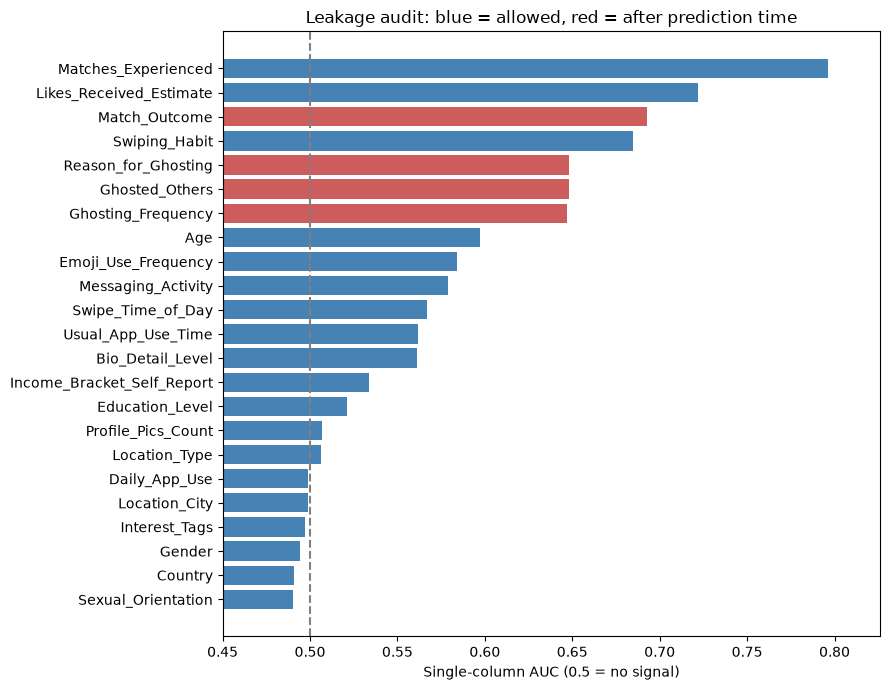

In [13]:
plt.figure(figsize=(9, 7))
colors = audit['role'].map({'available at prediction time': 'steelblue', 'after prediction time (leakage)': 'indianred'})
plt.barh(audit.index[::-1], audit['single_column_AUC'][::-1], color=colors[::-1])
plt.axvline(0.5, ls='--', c='grey')
plt.xlim(0.45, audit['single_column_AUC'].max() + 0.03)
plt.xlabel('Single-column AUC (0.5 = no signal)')
plt.title('Leakage audit: blue = allowed, red = after prediction time')
plt.tight_layout()
plt.show()

# 04 Exploratory Target Analysis

## CELL 14: Target Distribution

Ghosted_Experience
1    7130
0    6574
Name: count, dtype: int64
Ghosted_Experience
1    0.52
0    0.48
Name: proportion, dtype: float64


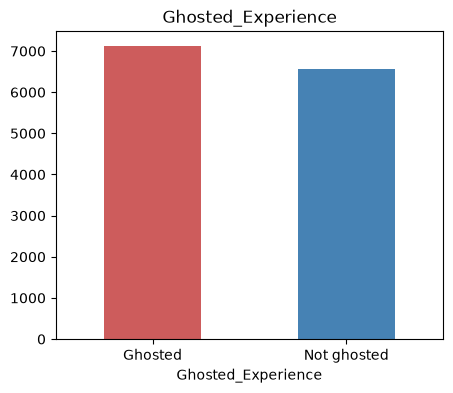

In [14]:
print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True).round(3))
df[TARGET].map({0: 'Not ghosted', 1: 'Ghosted'}).value_counts().plot(kind='bar', color=['indianred', 'steelblue'], figsize=(5, 4))
plt.title('Ghosted_Experience')
plt.xticks(rotation=0)
plt.show()

## CELL 15: Ghosting Rate Spread by Survey Question

In [15]:
# Purpose: Bigger spread between answers = the question separates ghosted users better
rows = []
for col in [c for c in PREDICTION_TIME_COLS if c != 'Interest_Tags']:
    grp = df.groupby(col)[TARGET].agg(['mean', 'size'])
    grp = grp[grp['size'] >= 100]
    rows.append({'feature': col, 'lowest_rate': grp['mean'].min(), 'highest_rate': grp['mean'].max(),
                 'spread': grp['mean'].max() - grp['mean'].min()})
rate_spread = pd.DataFrame(rows).set_index('feature').sort_values('spread', ascending=False).round(3)
rate_spread

,lowest_rate,highest_rate,spread
feature,,,
Matches_Experienced,0.000,0.980,0.980
Likes_Received_Estimate,0.081,0.901,0.819
Swiping_Habit,0.198,0.840,0.642
Age,0.338,0.680,0.342
Emoji_Use_Frequency,0.366,0.656,0.290
Bio_Detail_Level,0.436,0.668,0.232
Usual_App_Use_Time,0.389,0.612,0.223
Messaging_Activity,0.435,0.635,0.200
Swipe_Time_of_Day,0.438,0.618,0.180


## CELL 16: Visualize the Strongest Questions

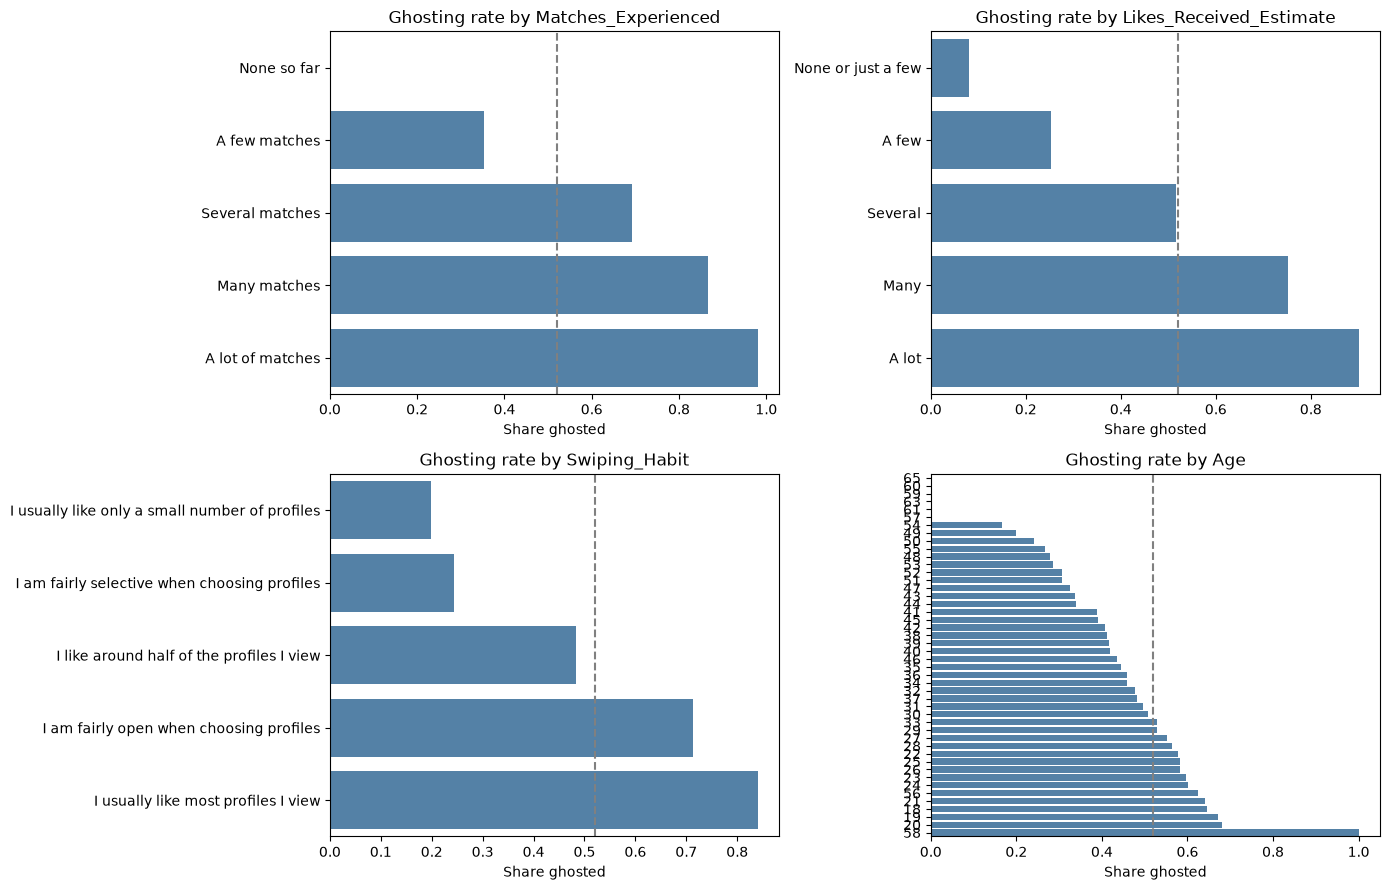

In [16]:
top4 = [c for c in rate_spread.index if c != 'Location_City'][:4]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), top4):
    rates = df.groupby(col)[TARGET].mean().sort_values()
    sns.barplot(x=rates.values, y=rates.index.astype(str), ax=ax, color='steelblue')
    ax.axvline(df[TARGET].mean(), ls='--', c='grey')
    ax.set_title(f'Ghosting rate by {col}')
    ax.set_xlabel('Share ghosted')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

## CELL 17: Matched vs Unmatched Users

In [17]:
has_match = df['Matches_Experienced'] != 'None so far'
summary = df.groupby(has_match.map({True: 'Has matches', False: 'No matches'}))[TARGET].agg(['size', 'mean']).round(3)
summary.columns = ['users', 'ghosted_rate']
print(summary)
print("\nYou cannot be ghosted without a match, so match exposure splits users into two very different groups.")

                     users  ghosted_rate
Matches_Experienced                     
Has matches          11764         0.606
No matches            1940         0.000

You cannot be ghosted without a match, so match exposure splits users into two very different groups.


## CELL 18: Out-of-Fold Accuracy from Answer Combinations

In [18]:
# Purpose: If we predict the majority outcome for every combination of the strongest answers,
# what accuracy does that give? (out-of-fold, diagnostic only - not a proof of a maximum)
def combination_accuracy(cols):
    key = df[cols].astype(str).agg('|'.join, axis=1)
    y = df[TARGET]
    correct = 0
    for tr, te in audit_cv.split(key, y):
        rate = y.iloc[tr].groupby(key.iloc[tr]).mean()
        pred = (key.iloc[te].map(rate).fillna(y.iloc[tr].mean()) >= 0.5).astype(int)
        correct += (pred.values == y.iloc[te].values).sum()
    return key.nunique(), correct / len(y)

combos = [top4[:1], top4[:2], top4[:3], top4]
ceiling = pd.DataFrame([{'questions': ' + '.join(c), 'combinations': combination_accuracy(c)[0],
                         'out_of_fold_accuracy': combination_accuracy(c)[1]} for c in combos]).round(3)
print(f"Majority-class accuracy: {max(df[TARGET].mean(), 1 - df[TARGET].mean()):.3f}")
ceiling

Majority-class accuracy: 0.520


,questions,combinations,out_of_fold_accuracy
0,Matches_Experienced,5,0.749
1,Matches_Experienced + Likes_Received_Estimate,20,0.749
2,Matches_Experienced + Likes_Received_Estimate ...,85,0.755
3,Matches_Experienced + Likes_Received_Estimate ...,1708,0.732


# 05 Create Raw + Engineered Features

Two feature sets are built from prediction-time columns only:

- **Raw:** original answers as categories (for CatBoost, which handles categories natively).
- **Engineered:** ordinal levels, derived scores and one-hot columns (for the other models).

Both are deterministic (no statistics learned from the data), so building them before the split does not leak information. `Location_City` is left out: 104 values, overlaps with `Location_Type`, and the audit shows weak signal.

## CELL 19: Ordinal Mappings for Ordered Survey Answers

In [19]:
ORDINAL_FEATURES = {
    'Daily_App_Use': ('App_Use_Minutes', {
        'Less than 15 minutes a day': 7.5, 'About 15–30 minutes a day': 22.5, 'About 30–60 minutes a day': 45,
        'About 1–2 hours a day': 90, 'More than 2 hours a day': 150}),
    'Swiping_Habit': ('Like_Ratio', {
        'I usually like only a small number of profiles': 0.1, 'I am fairly selective when choosing profiles': 0.3,
        'I like around half of the profiles I view': 0.5, 'I am fairly open when choosing profiles': 0.7,
        'I usually like most profiles I view': 0.9}),
    'Likes_Received_Estimate': ('Likes_Level', {
        'None or just a few': 0, 'A few': 1, 'Several': 2, 'Many': 3, 'A lot': 4}),
    'Matches_Experienced': ('Matches_Level', {
        'None so far': 0, 'A few matches': 1, 'Several matches': 2, 'Many matches': 3, 'A lot of matches': 4}),
    'Messaging_Activity': ('Messaging_Level', {
        'I usually have only a few messages with a match': 0, 'I usually have short conversations': 1,
        'I usually have moderately active conversations': 2, 'I am quite active in messaging matches': 3,
        'I am very active in messaging matches': 4}),
    'Emoji_Use_Frequency': ('Emoji_Level', {
        'Almost never': 0, 'Occasionally': 1, 'Sometimes': 2, 'Often': 3, 'Very often': 4}),
    'Bio_Detail_Level': ('Bio_Level', {
        'Very short (a line or less)': 0, 'Short (a few sentences)': 1, 'Medium (a short paragraph)': 2,
        'Detailed (several sentences/paragraphs)': 3, 'Very detailed': 4}),
    'Education_Level': ('Education_Score', {
        'High school': 0, 'Vocational / technical': 1, 'College / undergraduate': 2, 'Graduate': 3, 'Post-graduate': 4}),
    'Income_Bracket_Self_Report': ('Income_Level', {
        'Lower income range': 0, 'Middle income range': 1, 'Upper-middle income range': 2,
        'Higher income range': 3, 'Prefer not to say': 1}),
}
NIGHT = 'Late night / overnight (10 PM–5 AM)'
NOMINAL_COLS = ['Country', 'Gender', 'Sexual_Orientation', 'Location_Type', 'Usual_App_Use_Time', 'Swipe_Time_of_Day']
RAW_COLS = [c for c in PREDICTION_TIME_COLS if c not in ('Interest_Tags', 'Location_City')]

def clean_name(name):
    return re.sub(r'[^0-9A-Za-z]+', '_', str(name)).strip('_')

def map_ordinal(series, mapping):
    unmapped = set(series.unique()) - set(mapping)
    if unmapped:
        raise ValueError(f"{series.name}: no mapping for {unmapped}")
    return series.map(mapping)

print(f"{len(ORDINAL_FEATURES)} ordinal mappings defined")

9 ordinal mappings defined


## CELL 20: Build Raw Feature Set

In [20]:
def build_raw_features(data):
    tags = data['Interest_Tags'].str.get_dummies(sep=', ').add_prefix('Interest_')
    raw = pd.concat([data[RAW_COLS], tags], axis=1)
    raw.columns = [clean_name(c) for c in raw.columns]
    return raw

X_raw = build_raw_features(df)
CAT_COLS = X_raw.select_dtypes(include='object').columns.tolist()
print(f"Raw feature set: {X_raw.shape}, categorical columns: {len(CAT_COLS)}")

Raw feature set: (13704, 45), categorical columns: 15


## CELL 21: Build Engineered Feature Set

In [21]:
def build_engineered_features(data):
    out = pd.DataFrame(index=data.index)
    out['Age'] = data['Age']
    out['Profile_Pics_Count'] = data['Profile_Pics_Count']
    for src, (new_col, mapping) in ORDINAL_FEATURES.items():
        out[new_col] = map_ordinal(data[src], mapping)
    out['Income_Not_Disclosed'] = (data['Income_Bracket_Self_Report'] == 'Prefer not to say').astype(int)

    # Match exposure: you cannot be ghosted without a match
    out['Has_Any_Match'] = (out['Matches_Level'] > 0).astype(int)
    out['Like_Match_Gap'] = out['Likes_Level'] - out['Matches_Level']
    out['Open_Swiper_x_Matches'] = out['Like_Ratio'] * out['Matches_Level']
    out['Likes_x_Matches'] = out['Likes_Level'] * out['Matches_Level']
    out['Emoji_x_Matches'] = out['Emoji_Level'] * out['Matches_Level']

    # Composite scores (0-1)
    out['Engagement_Index'] = (out['App_Use_Minutes'] / 150 + out['Messaging_Level'] / 4 + out['Emoji_Level'] / 4) / 3
    out['Profile_Effort'] = (out['Profile_Pics_Count'] / 8 + out['Bio_Level'] / 4) / 2

    # Time-of-day behaviour
    out['Night_App_User'] = (data['Usual_App_Use_Time'] == NIGHT).astype(int)
    out['Night_Swiper'] = (data['Swipe_Time_of_Day'] == NIGHT).astype(int)
    out['Time_Mismatch'] = (data['Usual_App_Use_Time'] != data['Swipe_Time_of_Day']).astype(int)

    # Interests and nominal categories
    tags = data['Interest_Tags'].str.get_dummies(sep=', ').add_prefix('Interest_')
    out['Interest_Count'] = tags.sum(axis=1)
    age_group = pd.cut(data['Age'], bins=[17, 24, 34, 44, 100], labels=['18_24', '25_34', '35_44', '45_plus'])
    nominal = pd.get_dummies(data[NOMINAL_COLS].assign(Age_Group=age_group),
                             columns=NOMINAL_COLS + ['Age_Group'], dtype=int)
    out = pd.concat([out, tags, nominal], axis=1)
    out.columns = [clean_name(c) for c in out.columns]
    return out.astype(float)

# Built on the full survey so every answer option gets a column (no statistics are learned here)
X_eng = build_engineered_features(df)
y = df[TARGET]
assert X_eng.isnull().sum().sum() == 0 and X_eng.columns.is_unique
print(f"Engineered feature set: {X_eng.shape}")

Engineered feature set: (13704, 89)


## CELL 22: Engineered Feature Correlation with Target

In [22]:
corr = X_eng.corrwith(y).abs().sort_values(ascending=False).head(15).round(3)
print("Top 15 engineered features by |correlation| with target:")
print(corr)

Top 15 engineered features by |correlation| with target:
Matches_Level                                        0.546
Open_Swiper_x_Matches                                0.541
Likes_x_Matches                                      0.491
Has_Any_Match                                        0.423
Likes_Level                                          0.415
Emoji_x_Matches                                      0.383
Like_Ratio                                           0.348
Like_Match_Gap                                       0.183
Age                                                  0.179
Emoji_Level                                          0.161
Messaging_Level                                      0.144
Age_Group_18_24                                      0.131
Night_Swiper                                         0.123
Swipe_Time_of_Day_Late_night_overnight_10_PM_5_AM    0.123
Bio_Level                                            0.120
dtype: float64


# 05A Hypothesis Tests (H1-H3)

Statistical tests on the full survey, for both outcomes: **being ghosted** (`Ghosted_Experience`) and **ghosting others** (`Ghosted_Others`).

- **Chi-square test of independence** for each survey question, with **Cramér's V** as the effect size (below 0.1 negligible, 0.1-0.3 small, 0.3-0.5 medium, 0.5+ large). With about 13,700 answers even tiny differences reach p < 0.05, so the effect size decides whether a result matters.
- **Bonferroni correction** divides the 0.05 significance level by the number of tests.
- **Multivariable logistic regression** tests each factor while holding the others fixed (for example, open swipers also get more matches).

The survey has no response-time or message-length columns, so H3 is tested with the communication habits it does contain: emoji use and messaging activity.

## CELL 22A: Association Tests with Effect Sizes

In [23]:
OUTCOMES = {'Ghosted_Experience': 'being ghosted', 'Ghosted_Others': 'ghosting others'}
HYPOTHESIS_QUESTIONS = [
    ('H1', 'Swiping_Habit'),
    ('H2', 'Age_Group'),
    ('H2', 'Education_Level'),
    ('H2', 'Income_Bracket_Self_Report'),
    ('H3', 'Emoji_Use_Frequency'),
    ('H3', 'Messaging_Activity'),
    ('Reference', 'Gender'),
    ('Reference', 'Matches_Experienced'),
]
test_data = df.assign(Age_Group=pd.cut(df['Age'], bins=[17, 24, 34, 44, 100],
                                       labels=['18-24', '25-34', '35-44', '45+']).astype(str))
ALPHA = 0.05 / (len(HYPOTHESIS_QUESTIONS) * len(OUTCOMES))

def effect_label(v):
    return 'negligible' if v < 0.1 else 'small' if v < 0.3 else 'medium' if v < 0.5 else 'large'

rows = []
for hypothesis, question in HYPOTHESIS_QUESTIONS:
    for outcome, outcome_name in OUTCOMES.items():
        table = pd.crosstab(test_data[question], test_data[outcome])
        chi2, p, dof, _ = chi2_contingency(table)
        v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
        rows.append({'Hypothesis': hypothesis, 'Question': question, 'Outcome': outcome_name,
                     'Chi-square': round(chi2, 1), 'dof': dof, 'p-value': f"{p:.2e}", "Cramer's V": round(v, 3),
                     'Effect size': effect_label(v), 'Significant (Bonferroni)': p < ALPHA})
association_table = pd.DataFrame(rows)
print(f"Bonferroni-corrected significance level: {ALPHA:.5f}")
association_table

Bonferroni-corrected significance level: 0.00313


,Hypothesis,Question,Outcome,Chi-square,dof,p-value,Cramer's V,Effect size,Significant (Bonferroni)
0,H1,Swiping_Habit,being ghosted,1703.2,4,0.00e+00,0.353,medium,True
1,H1,Swiping_Habit,ghosting others,221.9,4,7.21e-47,0.127,small,True
2,H2,Age_Group,being ghosted,381.8,3,1.89e-82,0.167,small,True
3,H2,Age_Group,ghosting others,10.3,3,1.65e-02,0.027,negligible,False
4,H2,Education_Level,being ghosted,32.8,4,1.34e-06,0.049,negligible,True
5,H2,Education_Level,ghosting others,6.4,4,1.68e-01,0.022,negligible,False
6,H2,Income_Bracket_Self_Report,being ghosted,61.0,4,1.78e-12,0.067,negligible,True
7,H2,Income_Bracket_Self_Report,ghosting others,2.7,4,6.16e-01,0.014,negligible,False
8,H3,Emoji_Use_Frequency,being ghosted,370.5,4,6.63e-79,0.164,small,True
9,H3,Emoji_Use_Frequency,ghosting others,120.1,4,5.12e-25,0.094,negligible,True


## CELL 22B: H1 - Ghosting Others by Swiping Selectivity

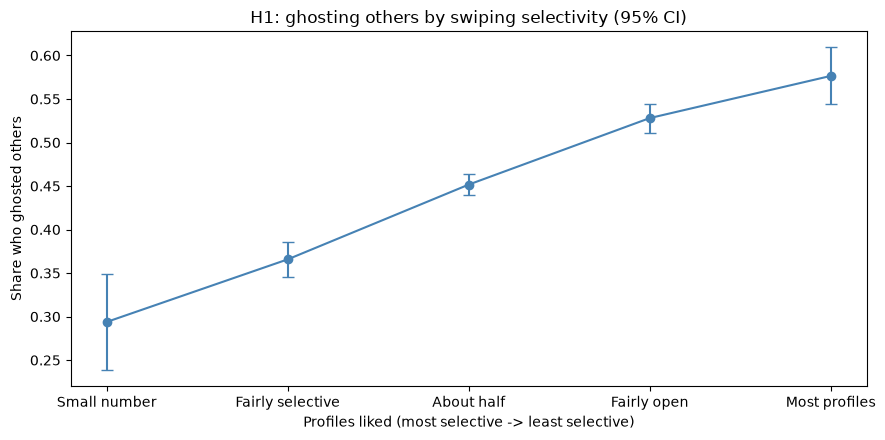

,mean,size,ci95
Swiping_Habit,,,
I usually like only a small number of profiles,0.294,262,0.055
I am fairly selective when choosing profiles,0.366,2209,0.020
I like around half of the profiles I view,0.452,6899,0.012
I am fairly open when choosing profiles,0.528,3458,0.017
I usually like most profiles I view,0.576,876,0.033


In [24]:
# Purpose: H1 says less selective swipers ghost others more. Answers are ordered from most to least selective
SWIPE_ORDER = ['I usually like only a small number of profiles', 'I am fairly selective when choosing profiles',
               'I like around half of the profiles I view', 'I am fairly open when choosing profiles',
               'I usually like most profiles I view']
assert set(SWIPE_ORDER) == set(df['Swiping_Habit'].unique())
h1 = df.groupby('Swiping_Habit')['Ghosted_Others'].agg(['mean', 'size']).reindex(SWIPE_ORDER)
h1['ci95'] = 1.96 * np.sqrt(h1['mean'] * (1 - h1['mean']) / h1['size'])

plt.figure(figsize=(9, 4.5))
plt.errorbar(range(len(h1)), h1['mean'], yerr=h1['ci95'], fmt='o-', capsize=4, color='steelblue')
plt.xticks(range(len(h1)), ['Small number', 'Fairly selective', 'About half', 'Fairly open', 'Most profiles'])
plt.xlabel('Profiles liked (most selective -> least selective)')
plt.ylabel('Share who ghosted others')
plt.title('H1: ghosting others by swiping selectivity (95% CI)')
plt.tight_layout()
plt.show()
h1.round(3)

## CELL 22C: Multivariable Logistic Regression (Odds Ratios)

In [25]:
# Purpose: Odds ratio > 1 = higher odds of the outcome per one step up, with all other factors held fixed
HYPOTHESIS_FEATURES = {
    'Like_Ratio': 'H1: share of profiles liked (0 -> 1)',
    'Age': 'H2: age (per 10 years)',
    'Education_Score': 'H2: education (per level)',
    'Income_Level': 'H2: income (per level)',
    'Income_Not_Disclosed': 'H2: income not disclosed',
    'Emoji_Level': 'H3: emoji use (per level)',
    'Messaging_Level': 'H3: messaging activity (per level)',
    'Matches_Level': 'Control: matches (per level)',
    'Likes_Level': 'Control: likes received (per level)',
}
X_hyp = X_eng[list(HYPOTHESIS_FEATURES)].copy()
X_hyp['Age'] = X_hyp['Age'] / 10

odds_tables = {}
for outcome, outcome_name in OUTCOMES.items():
    fit = sm.Logit(df[outcome].astype(int), sm.add_constant(X_hyp)).fit(disp=0)
    ci = np.exp(fit.conf_int())
    t = pd.DataFrame({'Odds ratio': np.exp(fit.params), 'CI 2.5%': ci[0], 'CI 97.5%': ci[1],
                      'p-value': fit.pvalues}).drop(index='const')
    t.index = [HYPOTHESIS_FEATURES[c] for c in t.index]
    odds_tables[outcome_name] = t
odds_ratio_table = pd.concat(odds_tables, axis=1)
odds_ratio_table.round(4)

being ghosted                            \
                                        Odds ratio  CI 2.5% CI 97.5% p-value   
H1: share of profiles liked (0 -> 1)       31.9452  23.7156  43.0305  0.0000   
H2: age (per 10 years)                      0.4341   0.4081   0.4617  0.0000   
H2: education (per level)                   0.9160   0.8766   0.9572  0.0001   
H2: income (per level)                      0.9866   0.9331   1.0431  0.6349   
H2: income not disclosed                    1.0319   0.8615   1.2359  0.7333   
H3: emoji use (per level)                   0.9440   0.9005   0.9895  0.0165   
H3: messaging activity (per level)          0.6405   0.6172   0.6646  0.0000   
Control: matches (per level)                4.6075   4.2716   4.9698  0.0000   
Control: likes received (per level)         1.3229   1.2376   1.4140  0.0000   

                                     ghosting others                           
                                          Odds ratio CI 2.5% CI 97.5% p-value  
H1: share of profiles liked (0 -> 1)          1.3645  1.0895   1.7089  0.0068  
H2: age (per 10 years)                        0.8968  0.8557   0.9397  0.0000  
H2: education (per level)                     0.9835  0.9493   1.0190  0.3577  
H2: income (per level)                        1.0241  0.9792   1.0710  0.2983  
H2: income not disclosed                      1.1226  0.9713   1.2974  0.1174  
H3: emoji use (per level)                     0.9862  0.9496   1.0243  0.4726  
H3: messaging activity (per level)            0.9344  0.9081   0.9614  0.0000  
Control: matches (per level)                  1.8840  1.7823   1.9915  0.0000  
Control: likes received (per level)           1.0377  0.9836   1.0948  0.1758

## CELL 22D: Odds Ratio Forest Plot

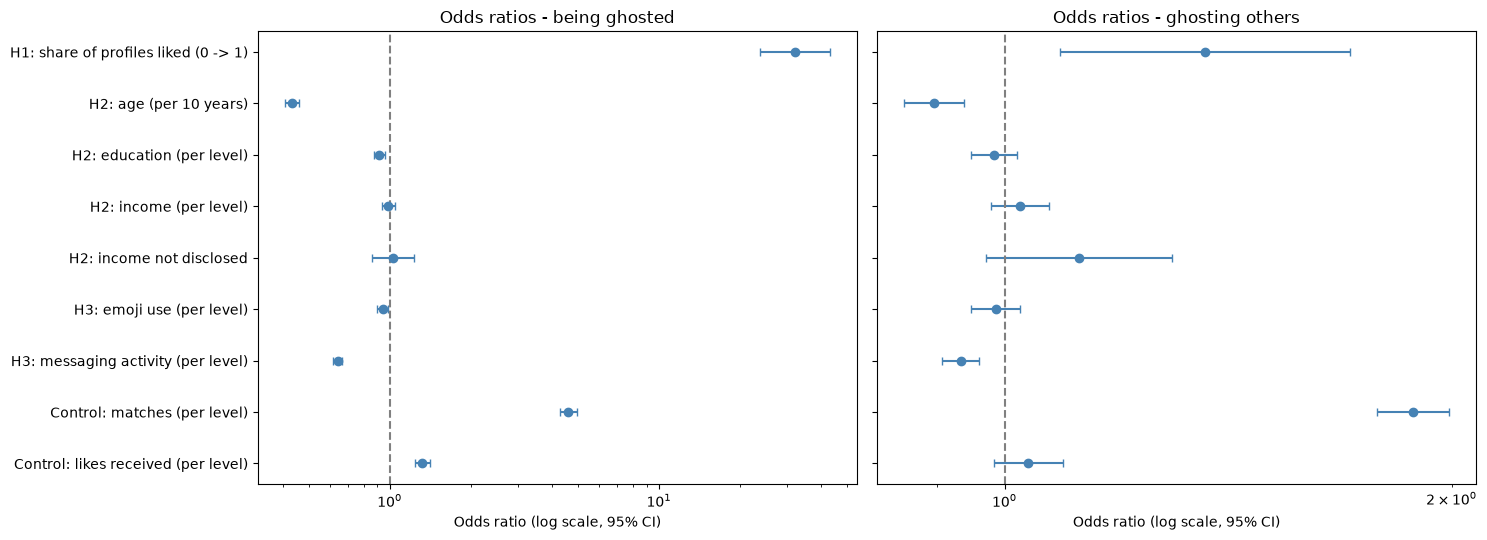

In [26]:
# Purpose: Odds ratios with 95% CI for both outcomes. The dashed line at 1 means "no effect"
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, (outcome_name, t) in zip(axes, odds_tables.items()):
    y_pos = np.arange(len(t))
    ax.errorbar(t['Odds ratio'], y_pos, xerr=[t['Odds ratio'] - t['CI 2.5%'], t['CI 97.5%'] - t['Odds ratio']],
                fmt='o', capsize=3, color='steelblue')
    ax.axvline(1, ls='--', c='grey')
    ax.set_xscale('log')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(t.index)
    ax.set_title(f'Odds ratios - {outcome_name}')
    ax.set_xlabel('Odds ratio (log scale, 95% CI)')
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

## CELL 22E: Effect Size by Survey Question

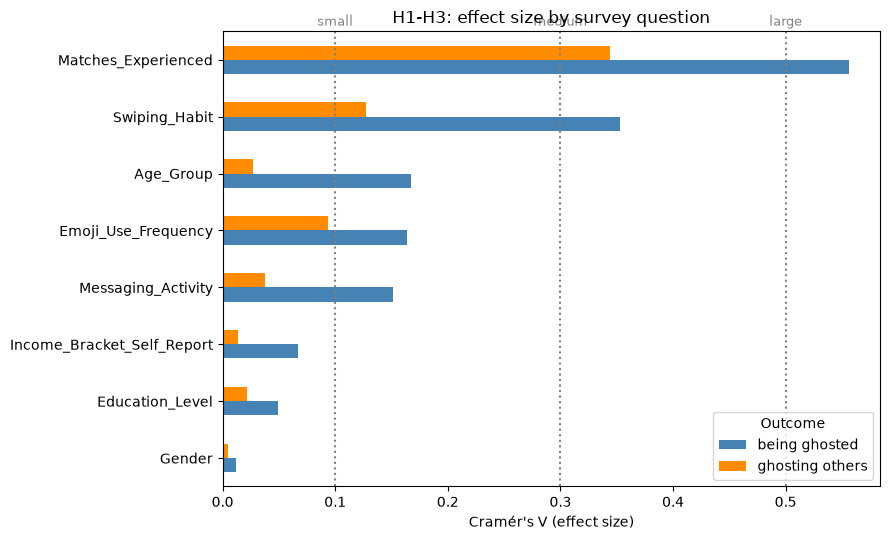

In [27]:
# Purpose: Effect size of every tested question for both outcomes (0.1 = small, 0.3 = medium, 0.5 = large)
effect_sizes = association_table.pivot(index='Question', columns='Outcome', values="Cramer's V").sort_values('being ghosted')
effect_sizes.plot.barh(figsize=(9, 5.5), color=['steelblue', 'darkorange'])
for x, label in [(0.1, 'small'), (0.3, 'medium'), (0.5, 'large')]:
    plt.axvline(x, ls=':', c='grey')
    plt.text(x, len(effect_sizes) - 0.4, label, ha='center', fontsize=9, color='grey')
plt.xlabel("Cramér's V (effect size)")
plt.ylabel('')
plt.title('H1-H3: effect size by survey question')
plt.tight_layout()
plt.show()

# 06 Split Train / Validation / Test

## CELL 23: Stratified 60 / 20 / 20 Split

In [28]:
# Purpose: Stratify on target AND match status so every split has the same mix of both
strata = y.astype(str) + '_' + X_eng['Has_Any_Match'].astype(int).astype(str)
idx_temp, idx_test = train_test_split(df.index, test_size=0.20, stratify=strata, random_state=RANDOM_STATE)
idx_train, idx_val = train_test_split(idx_temp, test_size=0.25, stratify=strata.loc[idx_temp], random_state=RANDOM_STATE)

def make_sets(idx):
    return {'eng': X_eng.loc[idx], 'cat': X_raw.loc[idx]}

sets_train, sets_val, sets_test = make_sets(idx_train), make_sets(idx_val), make_sets(idx_test)
y_train, y_val, y_test = y.loc[idx_train], y.loc[idx_val], y.loc[idx_test]

split_info = pd.DataFrame({
    'rows': [len(idx_train), len(idx_val), len(idx_test)],
    'ghosted_rate': [y_train.mean(), y_val.mean(), y_test.mean()],
    'has_match_rate': [sets_train['eng']['Has_Any_Match'].mean(), sets_val['eng']['Has_Any_Match'].mean(),
                       sets_test['eng']['Has_Any_Match'].mean()],
}, index=['train', 'validation', 'test']).round(3)
split_info

,rows,ghosted_rate,has_match_rate
train,8222,0.52,0.858
validation,2741,0.52,0.858
test,2741,0.52,0.858


## CELL 24: Evaluation Helpers

In [29]:
def evaluate(y_true, proba, threshold=0.5):
    y_true = np.asarray(y_true)
    pred = (proba >= threshold).astype(int)
    two_classes = len(np.unique(y_true)) > 1
    return {
        'Accuracy': accuracy_score(y_true, pred),
        'Balanced Accuracy': balanced_accuracy_score(y_true, pred) if two_classes else np.nan,
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall': recall_score(y_true, pred, zero_division=0),
        'F1': f1_score(y_true, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, proba) if two_classes else np.nan,
        'PR-AUC': average_precision_score(y_true, proba) if two_classes else np.nan,
    }

def report(name, y_true, proba, threshold=0.5):
    m = evaluate(y_true, proba, threshold)
    print(f"{name}: " + " | ".join(f"{k} {v:.4f}" for k, v in m.items()))

def oof_predictions(make_model, X, y_part, n_splits=5):
    # Out-of-fold probabilities: every row is predicted by a model that never saw it
    oof = np.zeros(len(y_part))
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    for tr, te in skf.split(X, y_part):
        model = make_model().fit(X.iloc[tr], y_part.iloc[tr])
        oof[te] = model.predict_proba(X.iloc[te])[:, 1]
    return oof

fitted_models = {}   # name -> (fitted model, feature set key)
val_proba = {}       # name -> validation probabilities (all users)
print("Helpers ready")

Helpers ready


# 07 Model 1: All Users

## CELL 25: Baselines

In [30]:
# Purpose: Any model must beat these simple references
majority_proba = np.full(len(y_val), y_train.mean())
print(f"Majority class ('Ghosted' for everyone) accuracy: {max(y_val.mean(), 1 - y_val.mean()):.4f}")
rule_proba = sets_val['eng']['Has_Any_Match'].values
report("Rule: ghosted if user has any match", y_val, rule_proba)

Majority class ('Ghosted' for everyone) accuracy: 0.5202
Rule: ghosted if user has any match: Accuracy 0.6618 | Balanced Accuracy 0.6475 | Precision 0.6060 | Recall 1.0000 | F1 0.7547 | ROC-AUC 0.6475 | PR-AUC 0.6060


## CELL 26: Logistic Regression

In [31]:
def make_lr():
    return Pipeline([('scaler', StandardScaler()),
                     ('clf', LogisticRegression(C=0.1, max_iter=5000))])

lr = make_lr().fit(sets_train['eng'], y_train)
fitted_models['Logistic Regression'] = (lr, 'eng')
val_proba['Logistic Regression'] = lr.predict_proba(sets_val['eng'])[:, 1]
report("Logistic Regression", y_val, val_proba['Logistic Regression'])

Logistic Regression: Accuracy 0.7982 | Balanced Accuracy 0.7967 | Precision 0.7900 | Recall 0.8338 | F1 0.8113 | ROC-AUC 0.8971 | PR-AUC 0.9027


## CELL 27: Random Forest

In [32]:
def make_rf():
    return RandomForestClassifier(n_estimators=400, min_samples_leaf=40, max_features='sqrt',
                                  n_jobs=-1, random_state=RANDOM_STATE)

rf = make_rf().fit(sets_train['eng'], y_train)
fitted_models['Random Forest'] = (rf, 'eng')
val_proba['Random Forest'] = rf.predict_proba(sets_val['eng'])[:, 1]
report("Random Forest", y_val, val_proba['Random Forest'])

Random Forest: Accuracy 0.7891 | Balanced Accuracy 0.7868 | Precision 0.7721 | Recall 0.8436 | F1 0.8063 | ROC-AUC 0.8809 | PR-AUC 0.8855


# 08 Model 2: Matched Users Only

Users with no matches are rarely or never ghosted, which makes them easy to predict. This model checks how well we can predict ghosting for the harder group: users who have matches.

## CELL 28: Matched-User Subsets

In [33]:
m_train = sets_train['eng']['Has_Any_Match'].values == 1
m_val = sets_val['eng']['Has_Any_Match'].values == 1
print(f"Matched users - train: {m_train.sum()}, validation: {m_val.sum()}")
print(f"Ghosted rate among matched users (validation): {y_val[m_val].mean():.3f}")
print(f"Majority-class accuracy among matched users: {max(y_val[m_val].mean(), 1 - y_val[m_val].mean()):.4f}")

Matched users - train: 7058, validation: 2353
Ghosted rate among matched users (validation): 0.606
Majority-class accuracy among matched users: 0.6060


## CELL 29: Train Matched-Only Models

In [34]:
def make_lightgbm():
    return LGBMClassifier(n_estimators=500, learning_rate=0.02, num_leaves=15, min_child_samples=40,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0,
                          verbose=-1, random_state=RANDOM_STATE)

matched_lr = make_lr().fit(sets_train['eng'][m_train], y_train[m_train])
matched_lgbm = make_lightgbm().fit(sets_train['eng'][m_train], y_train[m_train])
report("Matched-only Logistic Regression", y_val[m_val], matched_lr.predict_proba(sets_val['eng'][m_val])[:, 1])
report("Matched-only LightGBM          ", y_val[m_val], matched_lgbm.predict_proba(sets_val['eng'][m_val])[:, 1])
print("\nCompare with the all-user models above: users who have matches are the harder group to predict.")

Matched-only Logistic Regression: Accuracy 0.7637 | Balanced Accuracy 0.7447 | Precision 0.7881 | Recall 0.8345 | F1 0.8106 | ROC-AUC 0.8542 | PR-AUC 0.9028
Matched-only LightGBM          : Accuracy 0.7680 | Balanced Accuracy 0.7495 | Precision 0.7922 | Recall 0.8366 | F1 0.8138 | ROC-AUC 0.8512 | PR-AUC 0.8978

Compare with the all-user models above: users who have matches are the harder group to predict.


# 09 Hierarchical / Two-Stage Prediction

**Stage 1:** does the user have any match? If not, use the training ghosting rate of unmatched users.

**Stage 2:** for matched users, use a model trained only on matched users.

## CELL 30: Two-Stage Model Class

In [35]:
class TwoStageModel:
    def __init__(self, make_stage2, match_col='Has_Any_Match'):
        self.make_stage2 = make_stage2
        self.match_col = match_col

    def fit(self, X, y_part):
        matched = X[self.match_col].values == 1
        y_arr = np.asarray(y_part)
        self.unmatched_rate_ = y_arr[~matched].mean()
        self.stage2_ = self.make_stage2().fit(X[matched], y_arr[matched])
        return self

    def predict_proba(self, X):
        matched = X[self.match_col].values == 1
        p = np.full(len(X), self.unmatched_rate_)
        if matched.any():
            p[matched] = self.stage2_.predict_proba(X[matched])[:, 1]
        return np.column_stack([1 - p, p])

def make_two_stage():
    return TwoStageModel(make_stage2=make_lr)

print("TwoStageModel defined")

TwoStageModel defined


## CELL 31: Train and Evaluate Two-Stage Model

In [36]:
two_stage = make_two_stage().fit(sets_train['eng'], y_train)
fitted_models['Two-Stage'] = (two_stage, 'eng')
val_proba['Two-Stage'] = two_stage.predict_proba(sets_val['eng'])[:, 1]
print(f"Stage 1: ghosted rate for unmatched users (train) = {two_stage.unmatched_rate_:.3f}")
report("Two-Stage", y_val, val_proba['Two-Stage'])

Stage 1: ghosted rate for unmatched users (train) = 0.000
Two-Stage: Accuracy 0.7972 | Balanced Accuracy 0.7956 | Precision 0.7881 | Recall 0.8345 | F1 0.8106 | ROC-AUC 0.8972 | PR-AUC 0.9028


# 10 CatBoost

## CELL 32: Train CatBoost on Raw Categorical Features

In [37]:
# Purpose: CatBoost uses the original answers directly with ordered target statistics
def make_catboost():
    return CatBoostClassifier(iterations=600, learning_rate=0.04, depth=6, l2_leaf_reg=5,
                              cat_features=CAT_COLS, verbose=0, random_seed=RANDOM_STATE,
                              allow_writing_files=False)

catboost = make_catboost().fit(sets_train['cat'], y_train)
fitted_models['CatBoost'] = (catboost, 'cat')
val_proba['CatBoost'] = catboost.predict_proba(sets_val['cat'])[:, 1]
report("CatBoost", y_val, val_proba['CatBoost'])

CatBoost: Accuracy 0.8055 | Balanced Accuracy 0.8040 | Precision 0.7959 | Recall 0.8422 | F1 0.8184 | ROC-AUC 0.8979 | PR-AUC 0.9016


## CELL 33: CatBoost Feature Importance

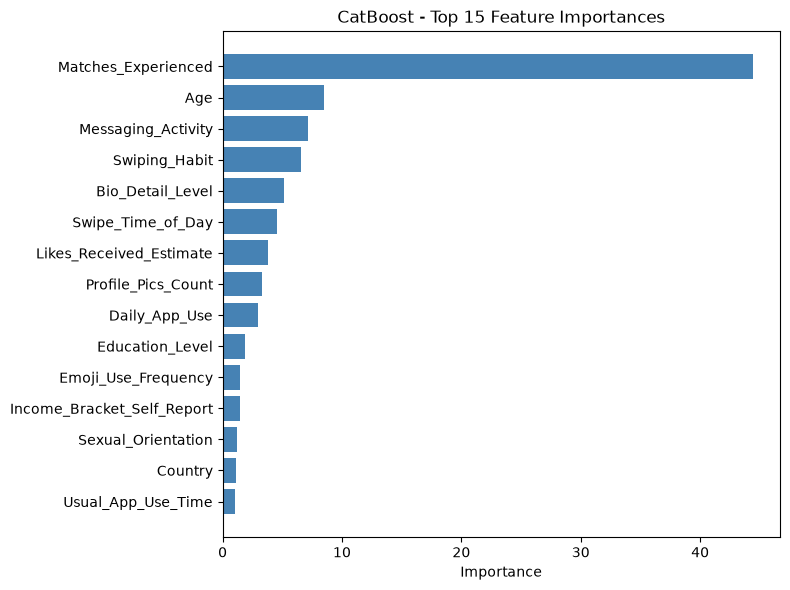

In [38]:
cb_importance = pd.Series(catboost.get_feature_importance(), index=sets_train['cat'].columns).sort_values(ascending=False)
top = cb_importance.head(15)[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color='steelblue')
plt.title('CatBoost - Top 15 Feature Importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

# 11 XGBoost / LightGBM

## CELL 34: Train XGBoost

In [39]:
def make_xgboost():
    return XGBClassifier(n_estimators=500, learning_rate=0.02, max_depth=3, subsample=0.8,
                         colsample_bytree=0.7, eval_metric='logloss', n_jobs=-1, random_state=RANDOM_STATE)

xgb = make_xgboost().fit(sets_train['eng'], y_train)
fitted_models['XGBoost'] = (xgb, 'eng')
val_proba['XGBoost'] = xgb.predict_proba(sets_val['eng'])[:, 1]
report("XGBoost", y_val, val_proba['XGBoost'])

XGBoost: Accuracy 0.8023 | Balanced Accuracy 0.8006 | Precision 0.7916 | Recall 0.8415 | F1 0.8158 | ROC-AUC 0.8976 | PR-AUC 0.9017


## CELL 35: Train LightGBM

In [40]:
lgbm = make_lightgbm().fit(sets_train['eng'], y_train)
fitted_models['LightGBM'] = (lgbm, 'eng')
val_proba['LightGBM'] = lgbm.predict_proba(sets_val['eng'])[:, 1]
report("LightGBM", y_val, val_proba['LightGBM'])

LightGBM: Accuracy 0.7986 | Balanced Accuracy 0.7970 | Precision 0.7894 | Recall 0.8359 | F1 0.8120 | ROC-AUC 0.8959 | PR-AUC 0.8994


## CELL 36: LightGBM Feature Importance (Gain)

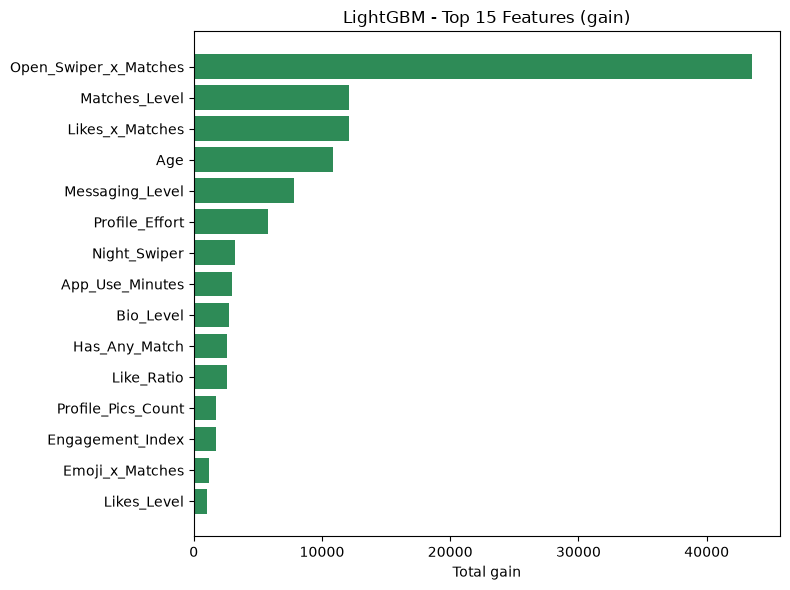

In [41]:
lgbm_importance = pd.Series(lgbm.booster_.feature_importance(importance_type='gain'),
                            index=sets_train['eng'].columns).sort_values(ascending=False)
top = lgbm_importance.head(15)[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color='seagreen')
plt.title('LightGBM - Top 15 Features (gain)')
plt.xlabel('Total gain')
plt.tight_layout()
plt.show()

# 12 Out-of-Fold Stacking

Each base model produces **out-of-fold** probabilities on the training set (every row predicted by a model that did not see it). A logistic regression meta-model learns how to combine them. Base models are then refit on the full training set for validation/test predictions.

## CELL 37: Define Base Models

In [42]:
BASE_SPECS = {
    'Logistic Regression': (make_lr, 'eng'),
    'Random Forest': (make_rf, 'eng'),
    'Two-Stage': (make_two_stage, 'eng'),
    'CatBoost': (make_catboost, 'cat'),
    'XGBoost': (make_xgboost, 'eng'),
    'LightGBM': (make_lightgbm, 'eng'),
}
print(f"Base models: {list(BASE_SPECS)}")

Base models: ['Logistic Regression', 'Random Forest', 'Two-Stage', 'CatBoost', 'XGBoost', 'LightGBM']


## CELL 38: Stacking Functions

In [43]:
def fit_stacking(base_specs, sets, y_part, n_splits=5):
    names = list(base_specs)
    oof = np.column_stack([oof_predictions(make, sets[key], y_part, n_splits) for make, key in base_specs.values()])
    meta = LogisticRegression(max_iter=5000).fit(oof, y_part)
    bases = {name: make().fit(sets[key], y_part) for name, (make, key) in base_specs.items()}
    return {'names': names, 'keys': {n: base_specs[n][1] for n in names}, 'bases': bases, 'meta': meta, 'oof': oof}

def predict_stacking(stack, sets):
    P = np.column_stack([stack['bases'][n].predict_proba(sets[stack['keys'][n]])[:, 1] for n in stack['names']])
    return stack['meta'].predict_proba(P)[:, 1]

print("Stacking functions ready")

Stacking functions ready


## CELL 39: Train Stacking Ensemble

In [44]:
stack = fit_stacking(BASE_SPECS, sets_train, y_train)
val_proba['Stacking Ensemble'] = predict_stacking(stack, sets_val)
report("Simple average of base-model OOF predictions (train)", y_train, stack['oof'].mean(axis=1))
report("Stacking Ensemble (validation)", y_val, val_proba['Stacking Ensemble'])

Simple average of base-model OOF predictions (train): Accuracy 0.8043 | Balanced Accuracy 0.8023 | Precision 0.7894 | Recall 0.8509 | F1 0.8190 | ROC-AUC 0.8937 | PR-AUC 0.8937
Stacking Ensemble (validation): Accuracy 0.8045 | Balanced Accuracy 0.8033 | Precision 0.8003 | Recall 0.8317 | F1 0.8157 | ROC-AUC 0.8996 | PR-AUC 0.9045


## CELL 40: Stacking Meta-Model Weights and Base Model Agreement

Meta-model weights (how much each base model is trusted):
XGBoost                2.186
CatBoost               1.696
Two-Stage              1.467
Logistic Regression    1.042
Random Forest          0.926
LightGBM              -0.970
dtype: float64

Base model prediction correlation: min 0.93, mean 0.97


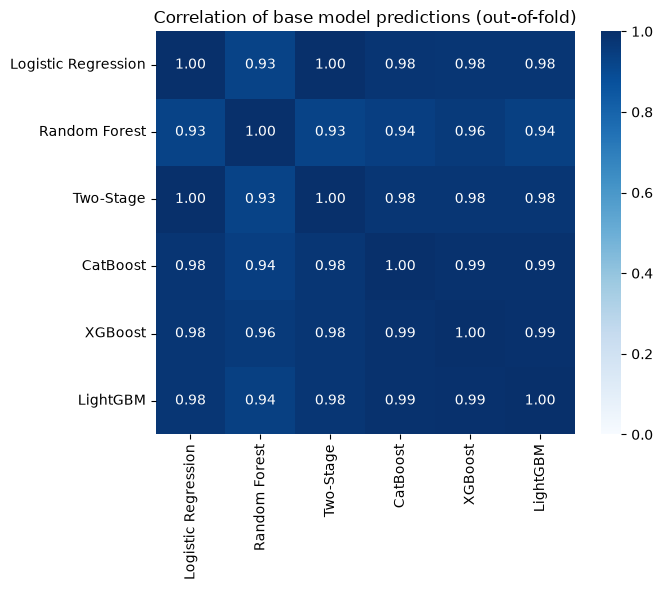

High correlation = base models learned the same pattern, so stacking has little extra to combine.


In [45]:
weights = pd.Series(stack['meta'].coef_[0], index=stack['names']).sort_values(ascending=False).round(3)
print("Meta-model weights (how much each base model is trusted):")
print(weights)

oof_corr = pd.DataFrame(stack['oof'], columns=stack['names']).corr()
off_diagonal = oof_corr.values[~np.eye(len(oof_corr), dtype=bool)]
print(f"\nBase model prediction correlation: min {off_diagonal.min():.2f}, mean {off_diagonal.mean():.2f}")
plt.figure(figsize=(7, 6))
sns.heatmap(oof_corr, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title('Correlation of base model predictions (out-of-fold)')
plt.tight_layout()
plt.show()
print("High correlation = base models learned the same pattern, so stacking has little extra to combine.")

# 12A Lean Features + Spline Logistic Regression

Interest tags and country dummies add about 40 columns that carry almost no signal. The **lean** feature set drops them.
**Spline logistic regression** turns every numeric answer into a smooth curve, so an answer can have a non-linear effect while the model stays simple and stable.

## CELL 40A: Lean Feature Set

In [46]:
# Purpose: Remove near-zero-signal columns to reduce noise
NOISY_PREFIXES = ('Interest_', 'Country_')
LEAN_COLS = [c for c in X_eng.columns if not c.startswith(NOISY_PREFIXES)]
SPLINE_COLS = [c for c in LEAN_COLS if X_eng[c].nunique() > 2]
BINARY_COLS = [c for c in LEAN_COLS if c not in SPLINE_COLS]
print(f"Lean feature set: {len(LEAN_COLS)} of {X_eng.shape[1]} columns "
      f"({len(SPLINE_COLS)} numeric -> splines, {len(BINARY_COLS)} binary)")

Lean feature set: 50 of 89 columns (17 numeric -> splines, 33 binary)


## CELL 40B: Spline Logistic Regression

In [47]:
def make_lean_lr():
    return Pipeline([('select', ColumnTransformer([('keep', 'passthrough', LEAN_COLS)])),
                     ('scaler', StandardScaler()),
                     ('clf', LogisticRegression(C=0.1, max_iter=5000))])

def make_spline_lr():
    return Pipeline([('features', ColumnTransformer([('splines', SplineTransformer(n_knots=4, degree=3), SPLINE_COLS),
                                                     ('binary', 'passthrough', BINARY_COLS)])),
                     ('scaler', StandardScaler()),
                     ('clf', LogisticRegression(C=0.1, max_iter=5000))])

# Purpose: Compare on 5-fold CV (training rows) before trusting one validation score
rows = []
for name, make in [('Logistic Regression (all features)', make_lr),
                   ('Logistic Regression (lean)', make_lean_lr),
                   ('Spline Logistic Regression (lean)', make_spline_lr)]:
    oof = oof_predictions(make, sets_train['eng'], y_train)
    rows.append({'Model': name, 'CV ROC-AUC (train)': roc_auc_score(y_train, oof)})

spline_lr = make_spline_lr().fit(sets_train['eng'], y_train)
fitted_models['Spline LR (lean)'] = (spline_lr, 'eng')
val_proba['Spline LR (lean)'] = spline_lr.predict_proba(sets_val['eng'])[:, 1]
report("Spline LR (lean)", y_val, val_proba['Spline LR (lean)'])
pd.DataFrame(rows).round(4)

Spline LR (lean): Accuracy 0.8066 | Balanced Accuracy 0.8049 | Precision 0.7943 | Recall 0.8478 | F1 0.8202 | ROC-AUC 0.9002 | PR-AUC 0.9050


,Model,CV ROC-AUC (train)
0,Logistic Regression (all features),0.8914
1,Logistic Regression (lean),0.8928
2,Spline Logistic Regression (lean),0.8944


# 12B Optuna Hyperparameter Tuning

Bayesian search (TPE sampler) over the settings of LightGBM, XGBoost and CatBoost. Every trial is scored with **5-fold cross-validation on the training rows only**, so the validation and test sets never influence the chosen settings.

## CELL 40C: Tuning Helper

In [48]:
N_TRIALS = {'LightGBM': 30, 'XGBoost': 30, 'CatBoost': 12}   # raise these for a longer, more thorough search
studies = {}

def tune(name, space, make_from_params, key):
    def objective(trial):
        params = space(trial)
        oof = oof_predictions(lambda: make_from_params(params), sets_train[key], y_train)
        return roc_auc_score(y_train, oof)
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=N_TRIALS[name])
    studies[name] = study
    print(f"{name}: best CV ROC-AUC {study.best_value:.4f} after {len(study.trials)} trials")
    print(f"  best settings: {study.best_params}")
    return study

## CELL 40D: Tune LightGBM

In [49]:
def lgbm_space(t):
    return dict(n_estimators=t.suggest_int('n_estimators', 200, 2000, step=100),
                learning_rate=t.suggest_float('learning_rate', 0.003, 0.1, log=True),
                num_leaves=t.suggest_int('num_leaves', 3, 63, log=True),
                min_child_samples=t.suggest_int('min_child_samples', 5, 300, log=True),
                subsample=t.suggest_float('subsample', 0.5, 1.0),
                colsample_bytree=t.suggest_float('colsample_bytree', 0.2, 1.0),
                reg_lambda=t.suggest_float('reg_lambda', 1e-3, 50, log=True),
                reg_alpha=t.suggest_float('reg_alpha', 1e-3, 10, log=True))

def make_lgbm_from(params):
    return LGBMClassifier(**params, subsample_freq=1, verbose=-1, random_state=RANDOM_STATE)

tune('LightGBM', lgbm_space, make_lgbm_from, 'eng');

LightGBM: best CV ROC-AUC 0.8935 after 30 trials
  best settings: {'n_estimators': 1800, 'learning_rate': 0.014909378150578786, 'num_leaves': 4, 'min_child_samples': 42, 'subsample': 0.7201380415188807, 'colsample_bytree': 0.6320755209273309, 'reg_lambda': 0.43362319930264404, 'reg_alpha': 0.05591854229703573}


## CELL 40E: Tune XGBoost

In [50]:
def xgb_space(t):
    return dict(n_estimators=t.suggest_int('n_estimators', 200, 2000, step=100),
                learning_rate=t.suggest_float('learning_rate', 0.003, 0.1, log=True),
                max_depth=t.suggest_int('max_depth', 2, 7),
                min_child_weight=t.suggest_float('min_child_weight', 0.5, 50, log=True),
                subsample=t.suggest_float('subsample', 0.5, 1.0),
                colsample_bytree=t.suggest_float('colsample_bytree', 0.2, 1.0),
                gamma=t.suggest_float('gamma', 1e-3, 5, log=True),
                reg_lambda=t.suggest_float('reg_lambda', 1e-2, 50, log=True))

def make_xgb_from(params):
    return XGBClassifier(**params, eval_metric='logloss', n_jobs=-1, random_state=RANDOM_STATE)

tune('XGBoost', xgb_space, make_xgb_from, 'eng');

XGBoost: best CV ROC-AUC 0.8936 after 30 trials
  best settings: {'n_estimators': 1100, 'learning_rate': 0.02460877779704968, 'max_depth': 2, 'min_child_weight': 1.2420311213660875, 'subsample': 0.5930653511390607, 'colsample_bytree': 0.5983418498693865, 'gamma': 0.0024238806441208853, 'reg_lambda': 0.5109374872566507}


## CELL 40F: Tune CatBoost

In [51]:
def catboost_space(t):
    return dict(iterations=t.suggest_int('iterations', 300, 1000, step=100),
                learning_rate=t.suggest_float('learning_rate', 0.01, 0.1, log=True),
                depth=t.suggest_int('depth', 3, 6),
                l2_leaf_reg=t.suggest_float('l2_leaf_reg', 1, 30, log=True),
                random_strength=t.suggest_float('random_strength', 0.1, 10, log=True),
                bagging_temperature=t.suggest_float('bagging_temperature', 0, 1))

def make_catboost_from(params):
    return CatBoostClassifier(**params, cat_features=CAT_COLS, verbose=0, random_seed=RANDOM_STATE,
                              allow_writing_files=False)

tune('CatBoost', catboost_space, make_catboost_from, 'cat');

CatBoost: best CV ROC-AUC 0.8934 after 12 trials
  best settings: {'iterations': 600, 'learning_rate': 0.019553708662745254, 'depth': 5, 'l2_leaf_reg': 1.6071238512039876, 'random_strength': 0.3839629299804172, 'bagging_temperature': 0.3663618432936917}


## CELL 40G: Refit Tuned Models

In [52]:
# Purpose: Refit each booster with its best settings on the full training set, then score it on validation
TUNED_SPECS = {
    'LightGBM (tuned)': (lambda: make_lgbm_from(studies['LightGBM'].best_params), 'eng'),
    'XGBoost (tuned)': (lambda: make_xgb_from(studies['XGBoost'].best_params), 'eng'),
    'CatBoost (tuned)': (lambda: make_catboost_from(studies['CatBoost'].best_params), 'cat'),
}
for name, (make, key) in TUNED_SPECS.items():
    model = make().fit(sets_train[key], y_train)
    fitted_models[name] = (model, key)
    val_proba[name] = model.predict_proba(sets_val[key])[:, 1]
    report(name, y_val, val_proba[name])

LightGBM (tuned): Accuracy 0.8008 | Balanced Accuracy 0.7992 | Precision 0.7906 | Recall 0.8394 | F1 0.8143 | ROC-AUC 0.8987 | PR-AUC 0.9027
XGBoost (tuned): Accuracy 0.7993 | Balanced Accuracy 0.7978 | Precision 0.7901 | Recall 0.8366 | F1 0.8127 | ROC-AUC 0.8996 | PR-AUC 0.9041
CatBoost (tuned): Accuracy 0.8034 | Balanced Accuracy 0.8014 | Precision 0.7893 | Recall 0.8485 | F1 0.8178 | ROC-AUC 0.8997 | PR-AUC 0.9037


## CELL 40H: Tuning Progress

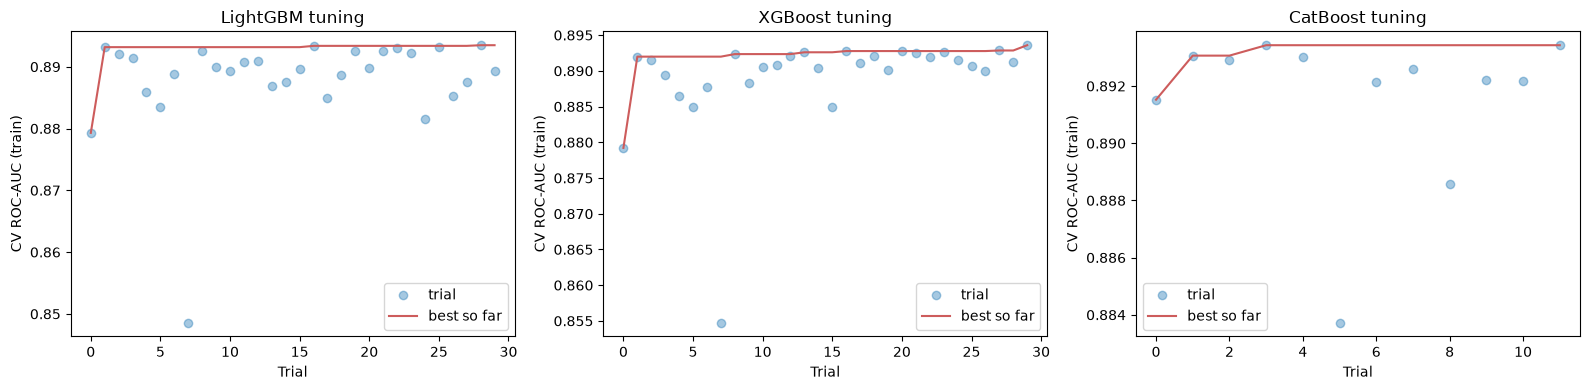

In [53]:
fig, axes = plt.subplots(1, len(studies), figsize=(16, 4))
for ax, (name, study) in zip(axes, studies.items()):
    values = [t.value for t in study.trials]
    ax.plot(values, 'o', alpha=0.4, label='trial')
    ax.plot(np.maximum.accumulate(values), c='indianred', label='best so far')
    ax.set_title(f'{name} tuning')
    ax.set_xlabel('Trial')
    ax.set_ylabel('CV ROC-AUC (train)')
    ax.legend()
plt.tight_layout()
plt.show()

# 12C Additional Model Families

Checks whether a different kind of learner (histogram boosting with native categories, a neural network, a kernel SVM, extremely randomized trees, nearest neighbours, naive Bayes) finds a pattern the linear and boosted-tree models miss.

## CELL 40I: Train Additional Model Families

In [54]:
# Answer options come from the full survey (no target information), same reasoning as the one-hot columns
CAT_LEVELS = {c: sorted(X_raw[c].astype(str).unique()) for c in CAT_COLS}

def to_category(X):
    X = X.copy()
    for c in CAT_COLS:
        X[c] = pd.Categorical(X[c].astype(str), categories=CAT_LEVELS[c])
    return X

EXTRA_SPECS = {
    'HistGradientBoosting': (lambda: Pipeline([
        ('to_category', FunctionTransformer(to_category)),
        ('clf', HistGradientBoostingClassifier(categorical_features='from_dtype', learning_rate=0.05, max_iter=400,
                                               max_leaf_nodes=15, l2_regularization=1.0, early_stopping=False,
                                               random_state=RANDOM_STATE))]), 'cat'),
    'Neural Network (MLP)': (lambda: Pipeline([
        ('scaler', StandardScaler()),
        ('clf', MLPClassifier((32,), alpha=0.1, early_stopping=True, max_iter=500, random_state=RANDOM_STATE))]), 'eng'),
    'SVM (RBF kernel)': (lambda: Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(C=1.0, probability=True, random_state=RANDOM_STATE))]), 'eng'),
    'Extra Trees': (lambda: ExtraTreesClassifier(n_estimators=600, min_samples_leaf=5, max_features=0.3,
                                                 n_jobs=-1, random_state=RANDOM_STATE), 'eng'),
    'K-Nearest Neighbors': (lambda: Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=75, weights='distance'))]), 'eng'),
    'Naive Bayes': (GaussianNB, 'eng'),
}
for name, (make, key) in EXTRA_SPECS.items():
    model = make().fit(sets_train[key], y_train)
    fitted_models[name] = (model, key)
    val_proba[name] = model.predict_proba(sets_val[key])[:, 1]
    report(name, y_val, val_proba[name])

HistGradientBoosting: Accuracy 0.7990 | Balanced Accuracy 0.7971 | Precision 0.7861 | Recall 0.8429 | F1 0.8135 | ROC-AUC 0.8925 | PR-AUC 0.8956
Neural Network (MLP): Accuracy 0.7877 | Balanced Accuracy 0.7863 | Precision 0.7825 | Recall 0.8198 | F1 0.8007 | ROC-AUC 0.8861 | PR-AUC 0.8904


C:\Users\ROG\AppData\Roaming\Python\Python312\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM (RBF kernel): Accuracy 0.7957 | Balanced Accuracy 0.7947 | Precision 0.7942 | Recall 0.8198 | F1 0.8068 | ROC-AUC 0.8856 | PR-AUC 0.8881
Extra Trees: Accuracy 0.7851 | Balanced Accuracy 0.7827 | Precision 0.7674 | Recall 0.8422 | F1 0.8031 | ROC-AUC 0.8800 | PR-AUC 0.8811
K-Nearest Neighbors: Accuracy 0.7621 | Balanced Accuracy 0.7587 | Precision 0.7371 | Recall 0.8436 | F1 0.7868 | ROC-AUC 0.8521 | PR-AUC 0.8518
Naive Bayes: Accuracy 0.7100 | Balanced Accuracy 0.6994 | Precision 0.6497 | Recall 0.9600 | F1 0.7750 | ROC-AUC 0.8429 | PR-AUC 0.8420


# 12D Advanced Stacking + Weighted Blend

Combines the strongest models: spline logistic regression and the three tuned boosters. Two ways of combining them:

- **Advanced Stacking:** out-of-fold probabilities feed a logistic regression meta-model (same method as section 12).
- **Weighted Blend:** non-negative weights that sum to 1, chosen to minimize out-of-fold log-loss.

## CELL 40J: Train Advanced Ensembles

In [55]:
ADVANCED_BASE_SPECS = {'Spline LR (lean)': (make_spline_lr, 'eng'), **TUNED_SPECS}
advanced_stack = fit_stacking(ADVANCED_BASE_SPECS, sets_train, y_train)

def base_matrix(stack_obj, sets):
    return np.column_stack([stack_obj['bases'][n].predict_proba(sets[stack_obj['keys'][n]])[:, 1]
                            for n in stack_obj['names']])

def fit_blend_weights(oof, y_part):
    k = oof.shape[1]
    loss = lambda w: log_loss(y_part, np.clip(oof @ (np.abs(w) / np.abs(w).sum()), 1e-6, 1 - 1e-6))
    w = np.abs(minimize(loss, np.full(k, 1 / k), method='Nelder-Mead', options={'maxiter': 4000}).x)
    return w / w.sum()

blend_weights = fit_blend_weights(advanced_stack['oof'], y_train)

# Every ensemble predicts from the feature-set dict, so later sections can score them like any other model
ENSEMBLES = {
    'Stacking Ensemble': lambda sets: predict_stacking(stack, sets),
    'Advanced Stacking': lambda sets: predict_stacking(advanced_stack, sets),
    'Weighted Blend': lambda sets: base_matrix(advanced_stack, sets) @ blend_weights,
}
for name in ['Advanced Stacking', 'Weighted Blend']:
    val_proba[name] = ENSEMBLES[name](sets_val)
    report(name, y_val, val_proba[name])

Advanced Stacking: Accuracy 0.8045 | Balanced Accuracy 0.8031 | Precision 0.7971 | Recall 0.8373 | F1 0.8167 | ROC-AUC 0.9010 | PR-AUC 0.9056
Weighted Blend: Accuracy 0.8063 | Balanced Accuracy 0.8046 | Precision 0.7946 | Recall 0.8464 | F1 0.8197 | ROC-AUC 0.9010 | PR-AUC 0.9058


## CELL 40K: Ensemble Weights and Base Model Agreement

In [56]:
print(pd.DataFrame({'Stacking meta coefficient': advanced_stack['meta'].coef_[0], 'Blend weight': blend_weights},
                   index=advanced_stack['names']).round(3))
adv_corr = pd.DataFrame(advanced_stack['oof'], columns=advanced_stack['names']).corr()
print(f"\nOut-of-fold prediction correlation between base models: mean "
      f"{adv_corr.values[~np.eye(len(adv_corr), dtype=bool)].mean():.3f}")
adv_corr.round(3)

                  Stacking meta coefficient  Blend weight
Spline LR (lean)                      2.295         0.616
LightGBM (tuned)                      0.226         0.089
XGBoost (tuned)                       0.413         0.065
CatBoost (tuned)                      3.060         0.230

Out-of-fold prediction correlation between base models: mean 0.991


,Spline LR (lean),LightGBM (tuned),XGBoost (tuned),CatBoost (tuned)
Spline LR (lean),1.000,0.990,0.991,0.985
LightGBM (tuned),0.990,1.000,0.999,0.990
XGBoost (tuned),0.991,0.999,1.000,0.990
CatBoost (tuned),0.985,0.990,0.990,1.000


# 13 Accuracy Threshold Optimization

## CELL 41: Tune Decision Threshold for Accuracy (Validation)

In [57]:
THRESHOLD_GRID = np.round(np.arange(0.30, 0.701, 0.005), 3)

def best_accuracy_threshold(y_true, proba):
    accs = np.array([accuracy_score(y_true, (proba >= t).astype(int)) for t in THRESHOLD_GRID])
    i = int(np.argmax(accs))
    return float(THRESHOLD_GRID[i]), accs

rows = []
thresholds = {}
for name, p in val_proba.items():
    thr, _ = best_accuracy_threshold(y_val, p)
    thresholds[name] = thr
    rows.append({'Model': name, 'Val ROC-AUC': roc_auc_score(y_val, p),
                 'Val Accuracy @0.50': accuracy_score(y_val, (p >= 0.5).astype(int)),
                 'Best threshold': thr,
                 'Val Accuracy @best': accuracy_score(y_val, (p >= thr).astype(int))})
validation_table = pd.DataFrame(rows).sort_values('Val ROC-AUC', ascending=False).reset_index(drop=True).round(4)
validation_table

,Model,Val ROC-AUC,Val Accuracy @0.50,Best threshold,Val Accuracy @best
0,Advanced Stacking,0.9010,0.8045,0.475,0.8092
1,Weighted Blend,0.9010,0.8063,0.450,0.8077
2,Spline LR (lean),0.9002,0.8066,0.465,0.8092
3,CatBoost (tuned),0.8997,0.8034,0.445,0.8066
4,Stacking Ensemble,0.8996,0.8045,0.500,0.8045
5,XGBoost (tuned),0.8996,0.7993,0.550,0.8066
6,LightGBM (tuned),0.8987,0.8008,0.435,0.8034
7,CatBoost,0.8979,0.8055,0.455,0.8070
8,XGBoost,0.8976,0.8023,0.425,0.8037
9,Two-Stage,0.8972,0.7972,0.530,0.8001


## CELL 42: Select Best Model

Selected model: Advanced Stacking
Accuracy-optimized threshold: 0.475


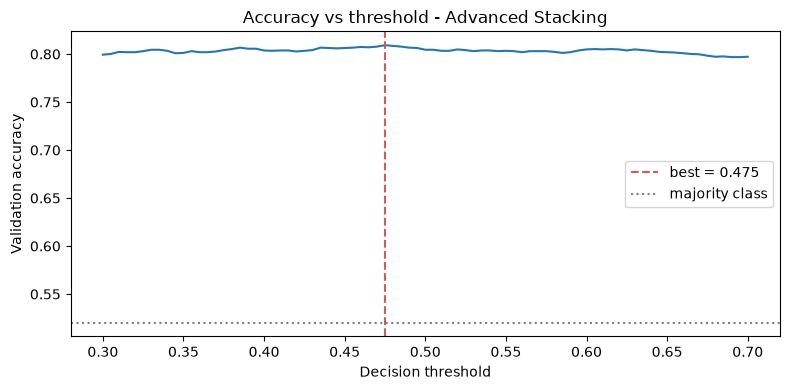

In [58]:
# Purpose: Select by validation ROC-AUC (threshold-free, less noisy than accuracy on ~2,700 rows)
best_name = validation_table.loc[0, 'Model']
best_threshold = thresholds[best_name]
print(f"Selected model: {best_name}")
print(f"Accuracy-optimized threshold: {best_threshold:.3f}")

_, accs = best_accuracy_threshold(y_val, val_proba[best_name])
plt.figure(figsize=(8, 4))
plt.plot(THRESHOLD_GRID, accs)
plt.axvline(best_threshold, ls='--', c='indianred', label=f'best = {best_threshold:.3f}')
plt.axhline(max(y_val.mean(), 1 - y_val.mean()), ls=':', c='grey', label='majority class')
plt.xlabel('Decision threshold')
plt.ylabel('Validation accuracy')
plt.title(f'Accuracy vs threshold - {best_name}')
plt.legend()
plt.tight_layout()
plt.show()

## CELL 43: Confident Predictions: Accuracy vs Coverage (Validation)

In [59]:
# Purpose: The model can answer only when it is confident and say "uncertain" otherwise.
# Coverage = share of users that receive a prediction. Always report both numbers together.
def coverage_table(y_true, proba, threshold, coverages=(1.0, 0.8, 0.6, 0.4, 0.3, 0.2, 0.1)):
    y_true = np.asarray(y_true)
    conf = np.abs(proba - threshold)
    order = np.argsort(-conf)
    correct = ((proba >= threshold).astype(int) == y_true)[order]
    rows = []
    for cov in coverages:
        k = int(round(cov * len(y_true)))
        rows.append({'coverage': cov, 'users_predicted': k, 'accuracy': correct[:k].mean(),
                     'min_confidence': conf[order[k - 1]]})
    return pd.DataFrame(rows).round(3)

def confidence_cutoff_for(y_true, proba, threshold, target_accuracy=0.80, min_coverage=0.05):
    y_true = np.asarray(y_true)
    conf = np.abs(proba - threshold)
    order = np.argsort(-conf)
    correct = ((proba >= threshold).astype(int) == y_true)[order]
    cum_acc = np.cumsum(correct) / np.arange(1, len(correct) + 1)
    start = max(int(min_coverage * len(correct)), 1) - 1
    ok = np.where(cum_acc[start:] >= target_accuracy)[0]
    if len(ok) == 0:
        return None
    pos = start + ok.max()
    return float(conf[order[pos]])

TARGET_CONFIDENT_ACCURACY = 0.90   # the overall accuracy is already about 80%, so 'confident' should mean more
print(coverage_table(y_val, val_proba[best_name], best_threshold))
confidence_cutoff = confidence_cutoff_for(y_val, val_proba[best_name], best_threshold, target_accuracy=TARGET_CONFIDENT_ACCURACY)
if confidence_cutoff is None:
    print(f"\nNo confidence level reaches {TARGET_CONFIDENT_ACCURACY:.0%} accuracy on validation.")
else:
    confident_val = np.abs(val_proba[best_name] - best_threshold) >= confidence_cutoff
    print(f"\nConfidence cutoff for >={TARGET_CONFIDENT_ACCURACY:.0%} validation accuracy: {confidence_cutoff:.3f}")
    print(f"Validation coverage: {confident_val.mean():.1%}, accuracy on covered users: "
          f"{accuracy_score(y_val[confident_val], (val_proba[best_name][confident_val] >= best_threshold).astype(int)):.3f}")

   coverage  users_predicted  accuracy  min_confidence
0       1.0             2741     0.809           0.000
1       0.8             2193     0.872           0.200
2       0.6             1645     0.931           0.338
3       0.4             1096     0.969           0.411
4       0.3              822     0.977           0.429
5       0.2              548     0.969           0.430
6       0.1              274     0.996           0.454

Confidence cutoff for >=90% validation accuracy: 0.269
Validation coverage: 71.3%, accuracy on covered users: 0.900


# 14 Subgroup Evaluation

## CELL 44: Subgroup Evaluation Helper

In [60]:
report_groups = pd.DataFrame({
    'Match status': np.where(df['Matches_Experienced'] == 'None so far', 'No matches', 'Has matches'),
    'Gender': df['Gender'],
    'Age group': pd.cut(df['Age'], bins=[17, 24, 34, 44, 100], labels=['18-24', '25-34', '35-44', '45+']).astype(str),
    'Country': df['Country'],
    'Location type': df['Location_Type'],
    'Sexual orientation': df['Sexual_Orientation'],
}, index=df.index)

def subgroup_table(groups, y_true, proba, threshold, min_n=30):
    y_true = np.asarray(y_true)
    rows = []
    for g in sorted(groups.unique()):
        m = (groups == g).values
        if m.sum() < min_n:
            continue
        pred = (proba[m] >= threshold).astype(int)
        rows.append({'group': g, 'n': int(m.sum()), 'ghosted_rate': y_true[m].mean(),
                     'predicted_ghosted_rate': pred.mean(), 'accuracy': accuracy_score(y_true[m], pred),
                     'ROC-AUC': roc_auc_score(y_true[m], proba[m]) if len(np.unique(y_true[m])) > 1 else np.nan})
    return pd.DataFrame(rows).set_index('group').round(3)

print("Subgroup helper ready")

Subgroup helper ready


## CELL 45: Subgroup Results on Validation Set

In [61]:
subgroup_results = {}
for col in report_groups.columns:
    t = subgroup_table(report_groups.loc[idx_val, col], y_val, val_proba[best_name], best_threshold)
    subgroup_results[col] = t
    print(f"\n=== {col} (accuracy gap: {t['accuracy'].max() - t['accuracy'].min():.3f}) ===")
    print(t)


=== Match status (accuracy gap: 0.222) ===
                n  ghosted_rate  predicted_ghosted_rate  accuracy  ROC-AUC
group                                                                     
Has matches  2353         0.606                   0.652     0.778     0.86
No matches    388         0.000                   0.000     1.000      NaN

=== Gender (accuracy gap: 0.017) ===
               n  ghosted_rate  predicted_ghosted_rate  accuracy  ROC-AUC
group                                                                    
Female      1340         0.520                   0.567     0.813    0.900
Male        1288         0.513                   0.554     0.807    0.904
Non-binary   113         0.602                   0.522     0.796    0.897

=== Age group (accuracy gap: 0.085) ===
          n  ghosted_rate  predicted_ghosted_rate  accuracy  ROC-AUC
group                                                               
18-24   725         0.633                   0.676     0.858    0.930


## CELL 46: Visualize Subgroup Accuracy

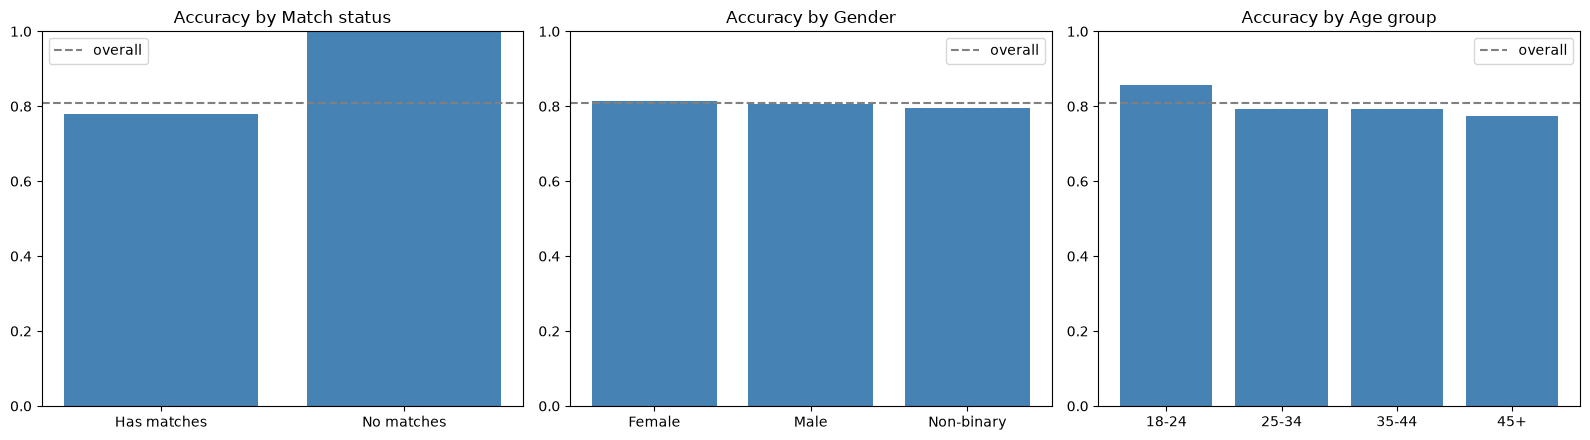

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['Match status', 'Gender', 'Age group']):
    t = subgroup_results[col]
    ax.bar(t.index.astype(str), t['accuracy'], color='steelblue')
    ax.axhline(accuracy_score(y_val, (val_proba[best_name] >= best_threshold).astype(int)), ls='--', c='grey', label='overall')
    ax.set_ylim(0, 1)
    ax.set_title(f'Accuracy by {col}')
    ax.legend()
plt.tight_layout()
plt.show()

# 15 Leakage Comparison

What happens if after-prediction-time columns are added? Same model (LightGBM), same training rows, 5-fold cross-validation. Higher scores here are **not** usable, because this information does not exist when the prediction is made.

## CELL 47: Build Leakage Feature Blocks

In [63]:
def dummies(col, prefix):
    d = pd.get_dummies(df[col], prefix=prefix, dtype=float)
    d.columns = [clean_name(c) for c in d.columns]
    return d

leak_blocks = {
    'Ghosted_Others + Ghosting_Frequency': pd.concat([df[['Ghosted_Others']].astype(float), dummies('Ghosting_Frequency', 'GhostFreq')], axis=1),
    'Reason_for_Ghosting': dummies('Reason_for_Ghosting', 'Reason'),
    'Match_Outcome': dummies('Match_Outcome', 'Outcome'),
}
feature_sets = {'Prediction-time features only (used)': X_eng}
for name, block in leak_blocks.items():
    feature_sets[f'+ {name}'] = pd.concat([X_eng, block], axis=1)
feature_sets['+ all after-time columns'] = pd.concat([X_eng] + list(leak_blocks.values()), axis=1)
print({k: v.shape[1] for k, v in feature_sets.items()})

{'Prediction-time features only (used)': 89, '+ Ghosted_Others + Ghosting_Frequency': 94, '+ Reason_for_Ghosting': 98, '+ Match_Outcome': 96, '+ all after-time columns': 110}


## CELL 48: Cross-Validated Leakage Comparison

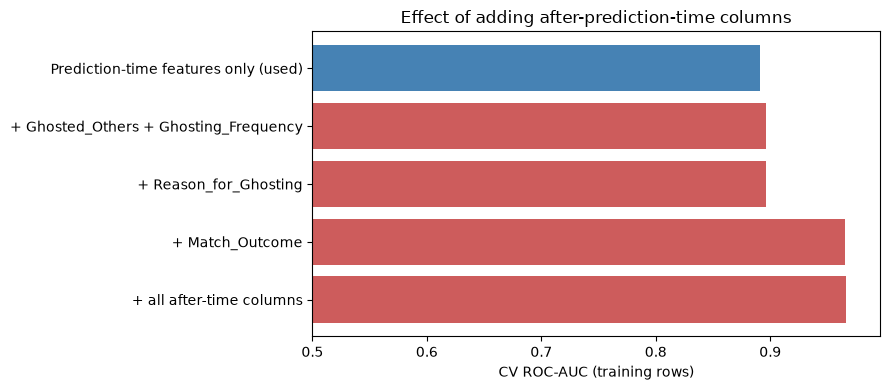

,Feature set,CV Accuracy,CV ROC-AUC
0,Prediction-time features only (used),0.7997,0.8910
1,+ Ghosted_Others + Ghosting_Frequency,0.8072,0.8965
2,+ Reason_for_Ghosting,0.8092,0.8967
3,+ Match_Outcome,0.8944,0.9651
4,+ all after-time columns,0.8949,0.9659


In [64]:
rows = []
for name, X_set in feature_sets.items():
    oof = oof_predictions(make_lightgbm, X_set.loc[idx_train], y_train)
    rows.append({'Feature set': name, 'CV Accuracy': accuracy_score(y_train, (oof >= 0.5).astype(int)),
                 'CV ROC-AUC': roc_auc_score(y_train, oof)})
leakage_table = pd.DataFrame(rows).round(4)

plt.figure(figsize=(9, 4))
plt.barh(leakage_table['Feature set'][::-1], leakage_table['CV ROC-AUC'][::-1],
         color=['indianred'] * (len(leakage_table) - 1) + ['steelblue'])
plt.xlim(0.5, leakage_table['CV ROC-AUC'].max() + 0.03)
plt.xlabel('CV ROC-AUC (training rows)')
plt.title('Effect of adding after-prediction-time columns')
plt.tight_layout()
plt.show()
leakage_table

# 16 Final Model

The model and threshold chosen on **validation** are now scored once on the untouched **test** set. The model is not refit, so the validation-tuned threshold and confidence cutoff apply exactly.

## CELL 49: Final Test Predictions

In [65]:
def predict_model(name, sets):
    if name in ENSEMBLES:
        return ENSEMBLES[name](sets)
    model, key = fitted_models[name]
    return model.predict_proba(sets[key])[:, 1]

test_proba = predict_model(best_name, sets_test)
test_pred = (test_proba >= best_threshold).astype(int)
print(f"Final model: {best_name} | threshold: {best_threshold:.3f}")

Final model: Advanced Stacking | threshold: 0.475


## CELL 50: Test Metrics: Final Model vs All Candidates

In [66]:
rows = []
for name in val_proba:
    p = predict_model(name, sets_test)
    rows.append({'Model': name, 'Threshold': thresholds[name], **evaluate(y_test, p, thresholds[name])})
test_table = pd.DataFrame(rows).sort_values('ROC-AUC', ascending=False).reset_index(drop=True).round(4)
test_table.to_csv('model_metric_summary_v2.csv', index=False)
print(f"Majority-class accuracy on test: {max(y_test.mean(), 1 - y_test.mean()):.4f}")
test_table

Majority-class accuracy on test: 0.5202


,Model,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Stacking Ensemble,0.500,0.8085,0.8073,0.8034,0.8366,0.8196,0.9018,0.9050
1,CatBoost,0.455,0.8085,0.8057,0.7832,0.8738,0.8260,0.9015,0.9045
2,Advanced Stacking,0.475,0.8074,0.8056,0.7950,0.8485,0.8209,0.9013,0.9046
3,Two-Stage,0.530,0.8045,0.8040,0.8103,0.8149,0.8126,0.9012,0.9049
4,Logistic Regression,0.530,0.8034,0.8030,0.8104,0.8121,0.8112,0.9012,0.9048
5,Weighted Blend,0.450,0.8045,0.8017,0.7799,0.8696,0.8223,0.9011,0.9048
6,XGBoost (tuned),0.550,0.8077,0.8075,0.8168,0.8128,0.8148,0.9005,0.9037
7,CatBoost (tuned),0.445,0.8059,0.8024,0.7719,0.8899,0.8267,0.9005,0.9031
8,Spline LR (lean),0.465,0.8012,0.7989,0.7826,0.8555,0.8174,0.9002,0.9043
9,LightGBM (tuned),0.435,0.8048,0.8015,0.7731,0.8843,0.8250,0.9001,0.9033


## CELL 50A: Test Accuracy and ROC-AUC for All Models

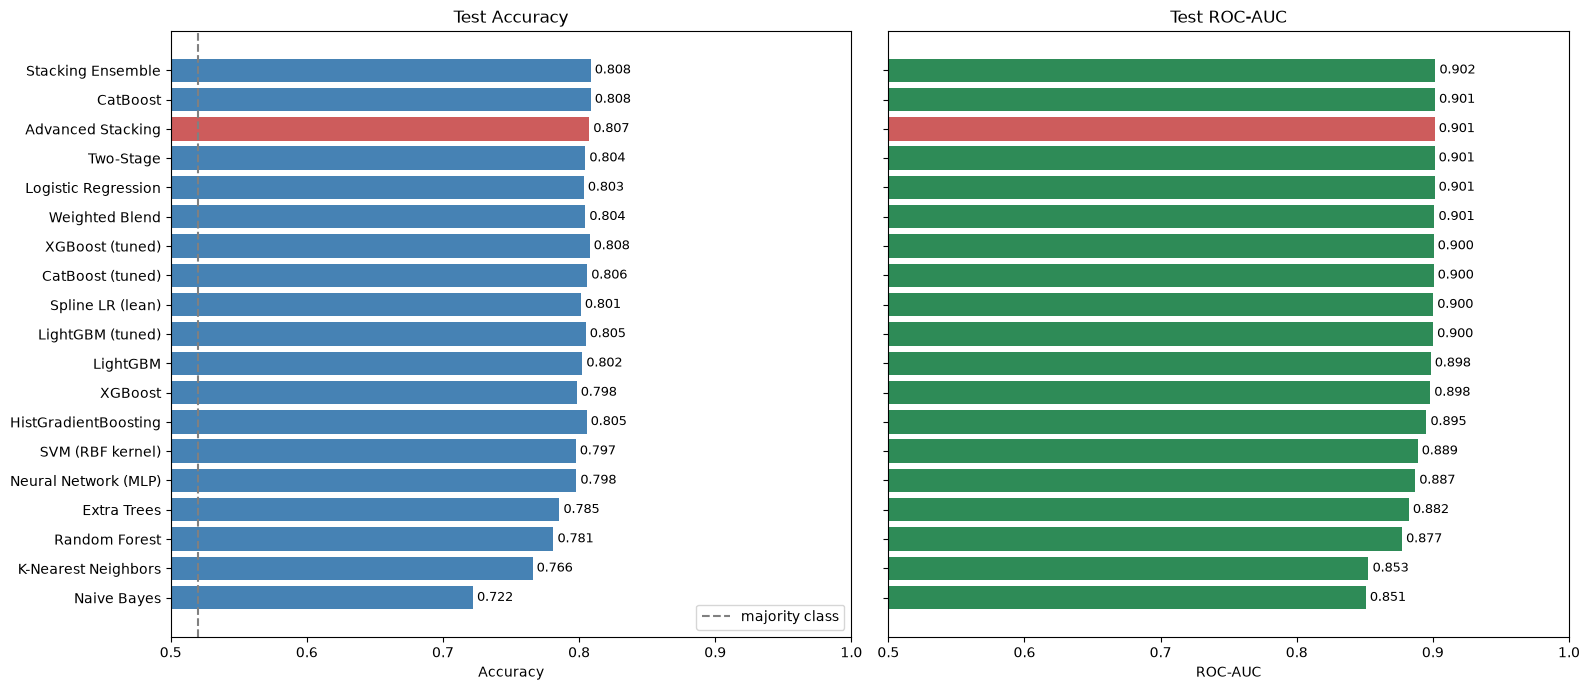

In [67]:
# Purpose: Compare every model on the untouched test set (final model in red, dashed line = majority class)
order = test_table.sort_values('ROC-AUC')
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
for ax, metric, color in zip(axes, ['Accuracy', 'ROC-AUC'], ['steelblue', 'seagreen']):
    ax.barh(order['Model'], order[metric], color=['indianred' if m == best_name else color for m in order['Model']])
    for y_pos, v in enumerate(order[metric]):
        ax.text(v + 0.003, y_pos, f'{v:.3f}', va='center', fontsize=9)
    ax.set_xlim(0.5, 1.0)
    ax.set_title(f'Test {metric}')
    ax.set_xlabel(metric)
axes[0].axvline(max(y_test.mean(), 1 - y_test.mean()), ls='--', c='grey', label='majority class')
axes[0].legend(loc='lower right')
plt.tight_layout()
plt.show()

## CELL 51: Classification Report and Confusion Matrix

              precision    recall  f1-score   support

 Not Ghosted       0.82      0.76      0.79      1315
     Ghosted       0.80      0.85      0.82      1426

    accuracy                           0.81      2741
   macro avg       0.81      0.81      0.81      2741
weighted avg       0.81      0.81      0.81      2741



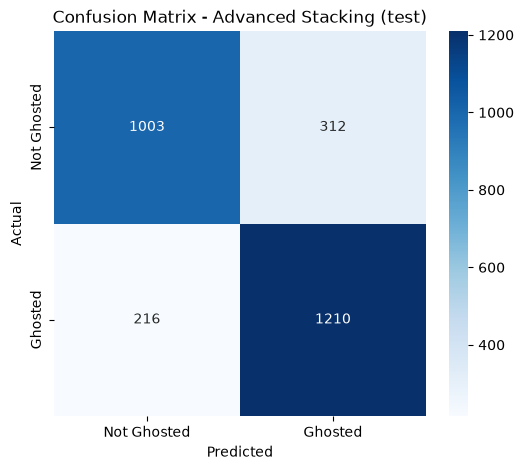

In [68]:
print(classification_report(y_test, test_pred, target_names=['Not Ghosted', 'Ghosted']))
cm = confusion_matrix(y_test, test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Ghosted', 'Ghosted'], yticklabels=['Not Ghosted', 'Ghosted'])
plt.title(f'Confusion Matrix - {best_name} (test)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## CELL 52: ROC Curves on Test Set

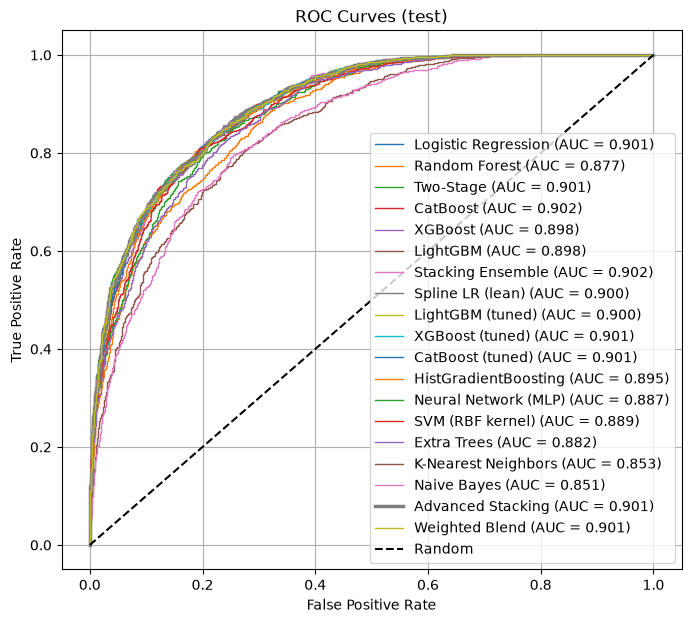

In [69]:
plt.figure(figsize=(8, 7))
for name in val_proba:
    p = predict_model(name, sets_test)
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2.5 if name == best_name else 1,
             label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves (test)')
plt.legend()
plt.grid(True)
plt.show()

## CELL 53: Confident Predictions on Test Set

In [70]:
print(coverage_table(y_test, test_proba, best_threshold))
if confidence_cutoff is not None:
    confident = np.abs(test_proba - best_threshold) >= confidence_cutoff
    test_is_unmatched = sets_test['eng']['Has_Any_Match'].values == 0
    print(f"\nUsing the validation cutoff ({confidence_cutoff:.3f}):")
    print(f"  Test coverage: {confident.mean():.1%} of users")
    print(f"  Accuracy on those users: {accuracy_score(y_test[confident], test_pred[confident]):.3f}")
    print(f"  Share of confident predictions that are users with no matches: {test_is_unmatched[confident].mean():.1%}")
    print(f"  Remaining {1 - confident.mean():.1%} of users are marked 'uncertain'")

   coverage  users_predicted  accuracy  min_confidence
0       1.0             2741     0.807           0.000
1       0.8             2193     0.870           0.207
2       0.6             1645     0.930           0.339
3       0.4             1096     0.969           0.412
4       0.3              822     0.972           0.428
5       0.2              548     0.962           0.430
6       0.1              274     0.982           0.454

Using the validation cutoff (0.269):
  Test coverage: 72.1% of users
  Accuracy on those users: 0.898
  Share of confident predictions that are users with no matches: 19.6%
  Remaining 27.9% of users are marked 'uncertain'


## CELL 54: Test Results by Match Status

In [71]:
subgroup_table(report_groups.loc[idx_test, 'Match status'], y_test, test_proba, best_threshold)

,n,ghosted_rate,predicted_ghosted_rate,accuracy,ROC-AUC
group,,,,,
Has matches,2353,0.606,0.647,0.776,0.86
No matches,388,0.000,0.000,1.000,NaN


## CELL 54A: Bootstrap 95% Confidence Intervals (Test)

In [72]:
# Purpose: The test set is one sample of users. Resampling it shows how much the scores could move by chance
rng = np.random.default_rng(RANDOM_STATE)
y_test_arr = np.asarray(y_test)
boot = {'Accuracy': [], 'Balanced Accuracy': [], 'ROC-AUC': [], 'F1': []}
for _ in range(1000):
    i = rng.integers(0, len(y_test_arr), len(y_test_arr))
    boot['Accuracy'].append(accuracy_score(y_test_arr[i], test_pred[i]))
    boot['Balanced Accuracy'].append(balanced_accuracy_score(y_test_arr[i], test_pred[i]))
    boot['ROC-AUC'].append(roc_auc_score(y_test_arr[i], test_proba[i]))
    boot['F1'].append(f1_score(y_test_arr[i], test_pred[i]))
point = evaluate(y_test, test_proba, best_threshold)
test_ci = pd.DataFrame({m: {'estimate': point[m], 'CI 2.5%': np.percentile(v, 2.5), 'CI 97.5%': np.percentile(v, 97.5)}
                        for m, v in boot.items()}).T.round(4)
test_ci

,estimate,CI 2.5%,CI 97.5%
Accuracy,0.8074,0.7920,0.8227
Balanced Accuracy,0.8056,0.7905,0.8206
ROC-AUC,0.9013,0.8905,0.9120
F1,0.8209,0.8062,0.8363


## CELL 54B: Probability Calibration (Test)

Brier score (lower is better): 0.1300


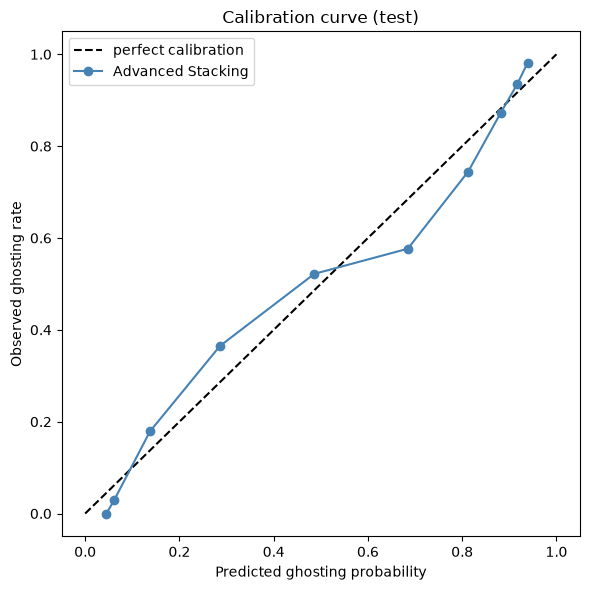

In [73]:
# Purpose: A well-calibrated model that says "70% risk" should be right about 70% of the time
prob_true, prob_pred = calibration_curve(y_test, test_proba, n_bins=10, strategy='quantile')
print(f"Brier score (lower is better): {brier_score_loss(y_test, test_proba):.4f}")
plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], 'k--', label='perfect calibration')
plt.plot(prob_pred, prob_true, 'o-', c='steelblue', label=best_name)
plt.xlabel('Predicted ghosting probability')
plt.ylabel('Observed ghosting rate')
plt.title('Calibration curve (test)')
plt.legend()
plt.tight_layout()
plt.show()

## CELL 54C: Survey Question Importance (Validation)

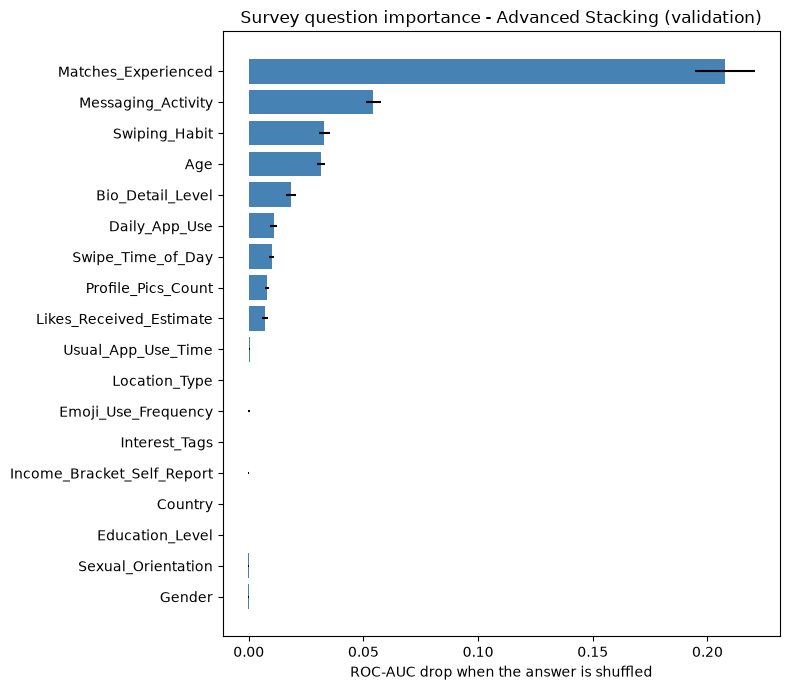

,Survey question,AUC drop,std
0,Matches_Experienced,0.2075,0.0131
1,Messaging_Activity,0.0543,0.0033
2,Swiping_Habit,0.0330,0.0024
3,Age,0.0315,0.0017
4,Bio_Detail_Level,0.0186,0.0022
5,Daily_App_Use,0.0109,0.0015
6,Swipe_Time_of_Day,0.0100,0.0012
7,Profile_Pics_Count,0.0081,0.0008
8,Likes_Received_Estimate,0.0071,0.0012
9,Usual_App_Use_Time,0.0004,0.0003


In [74]:
# Purpose: Shuffle one survey question at a time for validation users and measure the ROC-AUC drop.
# Both feature sets are rebuilt from the shuffled answers, so this works for every model, including ensembles
def rebuild_sets(data):
    return {'eng': build_engineered_features(data).reindex(columns=X_eng.columns, fill_value=0.0),
            'cat': build_raw_features(data).reindex(columns=X_raw.columns, fill_value=0)}

def question_importance_for(predict_fn, rows, y_true, repeats=5):
    rng = np.random.default_rng(RANDOM_STATE)
    base_auc = roc_auc_score(y_true, predict_fn(rebuild_sets(rows)))
    out = []
    for question in RAW_COLS + ['Interest_Tags']:
        drops = []
        for _ in range(repeats):
            shuffled = rows.copy()
            shuffled[question] = rng.permutation(shuffled[question].values)
            drops.append(base_auc - roc_auc_score(y_true, predict_fn(rebuild_sets(shuffled))))
        out.append({'Survey question': question, 'AUC drop': np.mean(drops), 'std': np.std(drops)})
    return pd.DataFrame(out).sort_values('AUC drop', ascending=False).reset_index(drop=True)

def plot_question_importance(table, title):
    top = table[::-1]
    plt.figure(figsize=(8, 7))
    plt.barh(top['Survey question'], top['AUC drop'], xerr=top['std'], color='steelblue')
    plt.title(title)
    plt.xlabel('ROC-AUC drop when the answer is shuffled')
    plt.tight_layout()
    plt.show()

val_rows = df.loc[idx_val]
assert np.allclose(rebuild_sets(val_rows)['eng'].values, sets_val['eng'].values)
question_importance = question_importance_for(lambda sets: predict_model(best_name, sets), val_rows, y_val)
plot_question_importance(question_importance, f'Survey question importance - {best_name} (validation)')
question_importance.round(4)

## CELL 55: Save Final Model

In [75]:
# Note: TwoStageModel, to_category and the ensemble helpers must be defined before loading this file again
ENSEMBLE_PARTS = {'Stacking Ensemble': {'stack': stack}, 'Advanced Stacking': {'stack': advanced_stack},
                  'Weighted Blend': {'stack': advanced_stack, 'weights': blend_weights}}
final_artifact = {
    'model_name': best_name,
    'model': ENSEMBLE_PARTS[best_name] if best_name in ENSEMBLE_PARTS else fitted_models[best_name][0],
    'threshold': best_threshold,
    'confidence_cutoff': confidence_cutoff,
    'ordinal_features': ORDINAL_FEATURES,
    'engineered_columns': list(X_eng.columns),
    'raw_columns': list(X_raw.columns),
    'cat_columns': CAT_COLS,
    'lean_columns': LEAN_COLS,
    'tuned_params': {name: study.best_params for name, study in studies.items()},
}
joblib.dump(final_artifact, 'ghosting_final_model_v2.pkl')
print("Saved: ghosting_final_model_v2.pkl, model_metric_summary_v2.csv")

Saved: ghosting_final_model_v2.pkl, model_metric_summary_v2.csv


## CELL 56: Final Summary

In [76]:
final_metrics = evaluate(y_test, test_proba, best_threshold)
print(f"Final model: {best_name}")
print(f"Decision threshold (tuned on validation): {best_threshold:.3f}")
print(f"Test accuracy:          {final_metrics['Accuracy']:.4f}  (majority class: {max(y_test.mean(), 1 - y_test.mean()):.4f})")
print(f"Test balanced accuracy: {final_metrics['Balanced Accuracy']:.4f}")
print(f"Test ROC-AUC:           {final_metrics['ROC-AUC']:.4f}")
print(f"Test F1:                {final_metrics['F1']:.4f}")
if confidence_cutoff is not None:
    confident = np.abs(test_proba - best_threshold) >= confidence_cutoff
    print(f"Confident predictions:  {accuracy_score(y_test[confident], test_pred[confident]):.4f} accuracy on {confident.mean():.1%} of test users")
print(f"\nLeakage check: after-time columns would raise CV AUC from "
      f"{leakage_table.loc[0, 'CV ROC-AUC']:.3f} to {leakage_table['CV ROC-AUC'].max():.3f} (not usable)")
print(f"Test ROC-AUC 95% CI:    {test_ci.loc['ROC-AUC', 'CI 2.5%']:.4f} - {test_ci.loc['ROC-AUC', 'CI 97.5%']:.4f}")
print(f"Test accuracy 95% CI:   {test_ci.loc['Accuracy', 'CI 2.5%']:.4f} - {test_ci.loc['Accuracy', 'CI 97.5%']:.4f}")
print(f"Models compared:        {len(val_proba)}")

Final model: Advanced Stacking
Decision threshold (tuned on validation): 0.475
Test accuracy:          0.8074  (majority class: 0.5202)
Test balanced accuracy: 0.8056
Test ROC-AUC:           0.9013
Test F1:                0.8209
Confident predictions:  0.8983 accuracy on 72.1% of test users

Leakage check: after-time columns would raise CV AUC from 0.891 to 0.966 (not usable)
Test ROC-AUC 95% CI:    0.8905 - 0.9120
Test accuracy 95% CI:   0.7920 - 0.8227
Models compared:        19


# 17 Second Target: Ghosting Others (H1)

The main model predicts **being ghosted**. H1 is about the user's **own** ghosting behaviour, so the pipeline is repeated with `Ghosted_Others` as the target: same prediction-time features, same train / validation / test rows, model and threshold chosen on validation, test scored once. `Ghosting_Frequency` and `Reason_for_Ghosting` describe this target directly, so they stay excluded.

## CELL 57: Train Models for Ghosting Others

In [77]:
y_others = df['Ghosted_Others'].astype(int)
yo_train, yo_val, yo_test = y_others.loc[idx_train], y_others.loc[idx_val], y_others.loc[idx_test]
print(f"Ghosted-others rate - train {yo_train.mean():.3f}, validation {yo_val.mean():.3f}, test {yo_test.mean():.3f}")

OTHERS_SPECS = {
    'Logistic Regression': (make_lr, 'eng'),
    'Spline LR (lean)': (make_spline_lr, 'eng'),
    'CatBoost': (make_catboost, 'cat'),
    'LightGBM': (make_lightgbm, 'eng'),
}
others_models, others_val = {}, {}
for name, (make, key) in OTHERS_SPECS.items():
    others_models[name] = (make().fit(sets_train[key], yo_train), key)
    others_val[name] = others_models[name][0].predict_proba(sets_val[key])[:, 1]
    report(name, yo_val, others_val[name])

Ghosted-others rate - train 0.458, validation 0.472, test 0.463
Logistic Regression: Accuracy 0.6107 | Balanced Accuracy 0.6126 | Precision 0.5788 | Recall 0.6463 | F1 0.6107 | ROC-AUC 0.6676 | PR-AUC 0.5916
Spline LR (lean): Accuracy 0.6045 | Balanced Accuracy 0.6064 | Precision 0.5729 | Recall 0.6402 | F1 0.6047 | ROC-AUC 0.6549 | PR-AUC 0.5720
CatBoost: Accuracy 0.6118 | Balanced Accuracy 0.6170 | Precision 0.5717 | Recall 0.7112 | F1 0.6339 | ROC-AUC 0.6573 | PR-AUC 0.5761
LightGBM: Accuracy 0.6060 | Balanced Accuracy 0.6080 | Precision 0.5740 | Recall 0.6440 | F1 0.6070 | ROC-AUC 0.6565 | PR-AUC 0.5868


## CELL 58: Test Results - Ghosting Others vs Being Ghosted

In [78]:
others_best = max(others_val, key=lambda n: roc_auc_score(yo_val, others_val[n]))
others_threshold, _ = best_accuracy_threshold(yo_val, others_val[others_best])
others_model, others_key = others_models[others_best]
others_test_proba = others_model.predict_proba(sets_test[others_key])[:, 1]
print(f"Selected on validation: {others_best} | threshold {others_threshold:.3f}")
print(f"Majority-class accuracy on test (ghosting others): {max(yo_test.mean(), 1 - yo_test.mean()):.4f}")
others_metrics = pd.DataFrame({
    f'Ghosting others ({others_best})': evaluate(yo_test, others_test_proba, others_threshold),
    f'Being ghosted ({best_name})': evaluate(y_test, test_proba, best_threshold),
}).T.round(4)
others_metrics

Selected on validation: Logistic Regression | threshold 0.470
Majority-class accuracy on test (ghosting others): 0.5374


,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Ghosting others (Logistic Regression),0.6034,0.6153,0.5508,0.7744,0.6437,0.6541,0.5748
Being ghosted (Advanced Stacking),0.8074,0.8056,0.7950,0.8485,0.8209,0.9013,0.9046


## CELL 58A: Confusion Matrix and ROC Curves - Ghosting Others

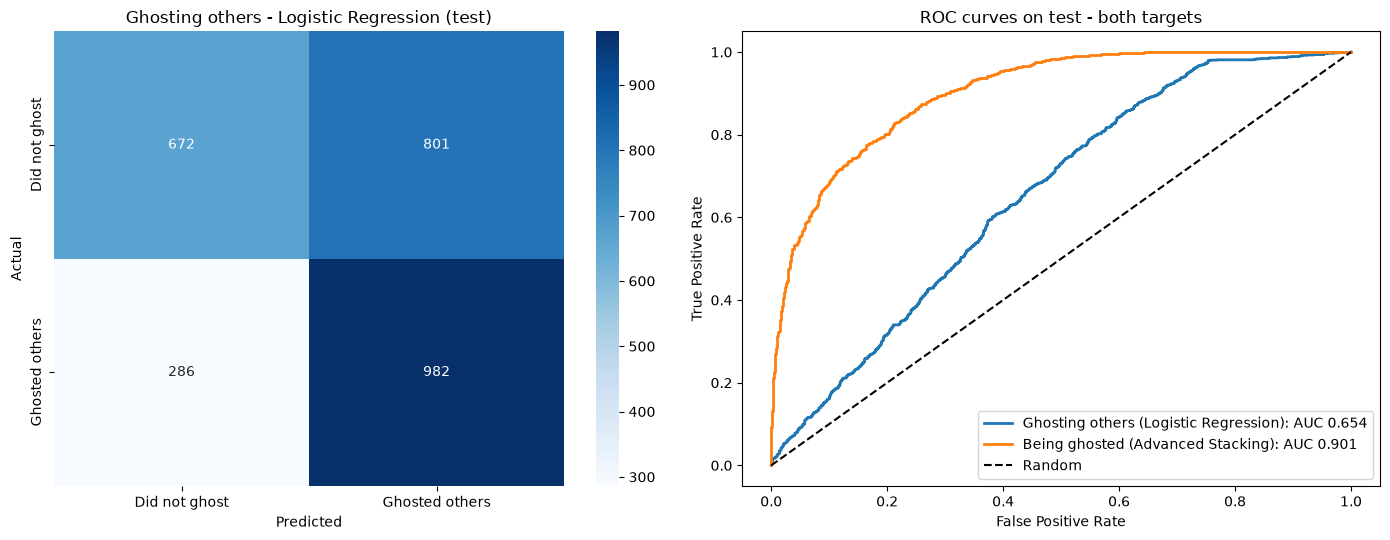

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
others_pred = (others_test_proba >= others_threshold).astype(int)
sns.heatmap(confusion_matrix(yo_test, others_pred), annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Did not ghost', 'Ghosted others'], yticklabels=['Did not ghost', 'Ghosted others'])
axes[0].set_title(f'Ghosting others - {others_best} (test)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
for label, y_true, proba in [(f'Ghosting others ({others_best})', yo_test, others_test_proba),
                             (f'Being ghosted ({best_name})', y_test, test_proba)]:
    fpr, tpr, _ = roc_curve(y_true, proba)
    axes[1].plot(fpr, tpr, lw=2, label=f'{label}: AUC {roc_auc_score(y_true, proba):.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC curves on test - both targets')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

## CELL 59: Survey Question Importance - Ghosting Others (Validation)

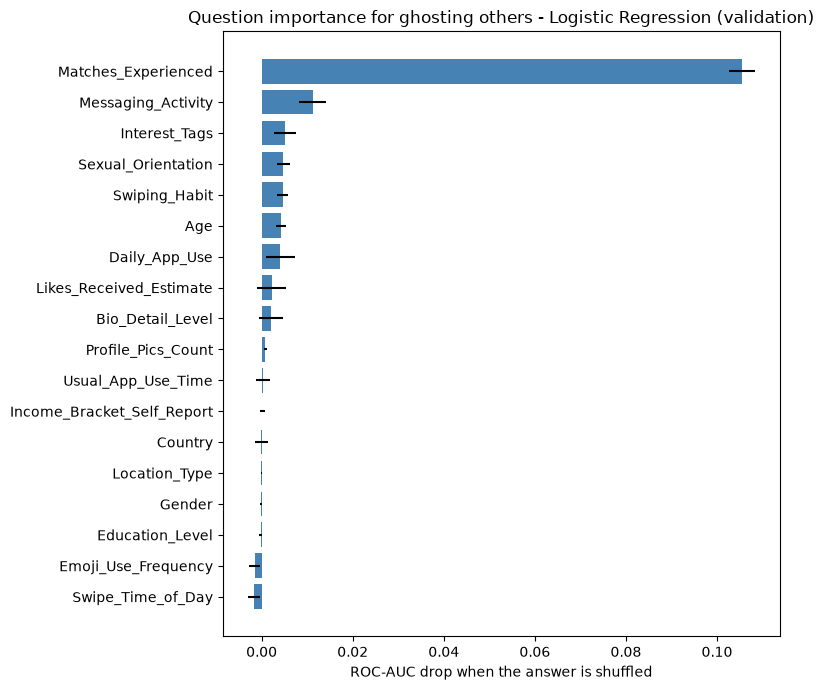

,Survey question,AUC drop,std
0,Matches_Experienced,0.1055,0.0028
1,Messaging_Activity,0.0112,0.0030
2,Interest_Tags,0.0051,0.0024
3,Sexual_Orientation,0.0047,0.0014
4,Swiping_Habit,0.0046,0.0011
5,Age,0.0042,0.0011
6,Daily_App_Use,0.0041,0.0031
7,Likes_Received_Estimate,0.0022,0.0032
8,Bio_Detail_Level,0.0021,0.0027
9,Profile_Pics_Count,0.0008,0.0003


In [80]:
others_importance = question_importance_for(lambda sets: others_model.predict_proba(sets[others_key])[:, 1],
                                            val_rows, yo_val)
plot_question_importance(others_importance, f'Question importance for ghosting others - {others_best} (validation)')
others_importance.round(4)

# 18 Deployable Model Export

For the Ghost Guard API, **Spline LR (lean)** is exported: plain scikit-learn, fast, easy to explain, and within noise of the best ensemble in this notebook. It is saved with its validation-tuned threshold and everything needed to turn survey answers into model features.

## CELL 60: Export Scikit-learn Model

In [81]:
deploy_name = 'Spline LR (lean)'
deploy_model, deploy_key = fitted_models[deploy_name]
deploy_threshold = thresholds[deploy_name]
deploy_test = evaluate(y_test, deploy_model.predict_proba(sets_test[deploy_key])[:, 1], deploy_threshold)
print(f"{deploy_name} on test: " + " | ".join(f"{k} {v:.4f}" for k, v in deploy_test.items()))
print(f"Best model ({best_name}) on test: ROC-AUC {final_metrics['ROC-AUC']:.4f} | Accuracy {final_metrics['Accuracy']:.4f}")

deploy_artifact = {
    'model': deploy_model,
    'threshold': deploy_threshold,
    'feature_columns': list(X_eng.columns),
    'ordinal_features': ORDINAL_FEATURES,
    'nominal_columns': NOMINAL_COLS,
    'night_label': NIGHT,
    'input_questions': RAW_COLS + ['Interest_Tags'],
    'test_metrics': deploy_test,
}
joblib.dump(deploy_artifact, 'ghosting_spline_lr_deploy.pkl')
print("Saved: ghosting_spline_lr_deploy.pkl (scikit-learn only)")

Spline LR (lean) on test: Accuracy 0.8012 | Balanced Accuracy 0.7989 | Precision 0.7826 | Recall 0.8555 | F1 0.8174 | ROC-AUC 0.9002 | PR-AUC 0.9043
Best model (Advanced Stacking) on test: ROC-AUC 0.9013 | Accuracy 0.8074
Saved: ghosting_spline_lr_deploy.pkl (scikit-learn only)


## CELL 61: Example API Prediction for One User

In [82]:
# Purpose: How an API scores one new user: survey answers -> engineered features -> probability
def predict_ghosting_risk(answers, artifact=deploy_artifact):
    row = pd.DataFrame([answers])
    features = build_engineered_features(row).reindex(columns=artifact['feature_columns'], fill_value=0.0)
    probability = float(artifact['model'].predict_proba(features)[:, 1][0])
    return {'ghosting_probability': round(probability, 3), 'predicted_ghosted': probability >= artifact['threshold']}

example = df.loc[idx_test[0], RAW_COLS + ['Interest_Tags']].to_dict()
print(example)
print(predict_ghosting_risk(example))
single = predict_ghosting_risk(example)['ghosting_probability']
batch = deploy_model.predict_proba(sets_test[deploy_key].loc[[idx_test[0]]])[:, 1][0]
assert abs(single - batch) < 1e-3, "single-user path must match the batch features"

{'Country': 'New Zealand', 'Age': 21, 'Gender': 'Male', 'Sexual_Orientation': 'Bisexual', 'Location_Type': 'Urban', 'Education_Level': 'High school', 'Income_Bracket_Self_Report': 'Middle income range', 'Daily_App_Use': 'More than 2 hours a day', 'Swiping_Habit': 'I like around half of the profiles I view', 'Likes_Received_Estimate': 'Several', 'Matches_Experienced': 'A few matches', 'Messaging_Activity': 'I am quite active in messaging matches', 'Emoji_Use_Frequency': 'Sometimes', 'Usual_App_Use_Time': 'Evening (5–10 PM)', 'Swipe_Time_of_Day': 'Late night / overnight (10 PM–5 AM)', 'Profile_Pics_Count': 2, 'Bio_Detail_Level': 'Medium (a short paragraph)', 'Interest_Tags': 'Travel, Cooking, Fitness, Books'}
{'ghosting_probability': 0.877, 'predicted_ghosted': True}


### Interpretation

**Main result: predicting whether a user is ghosted**

- The final model (**Advanced Stacking**, chosen on validation) reaches **80.7% test accuracy** (95% CI 79.2-82.3%) and **ROC-AUC 0.901** (95% CI 0.891-0.912). Always predicting the majority class gives 52.0%. Balanced accuracy is 80.6%, so both classes are predicted about equally well (recall 0.76 for not ghosted, 0.85 for ghosted).
- **The choice of algorithm matters little.** 19 models were compared. The top 12 (logistic regression, spline logistic regression, tuned and untuned boosted trees, two-stage, stacking and blending) all score between 0.898 and 0.902 test ROC-AUC, well inside the final model's confidence interval. Optuna tuning raised cross-validated ROC-AUC by only 0.001-0.003, and the base models' out-of-fold predictions correlate at 0.99, so the ensembles have little extra to combine.
- **Deployable model:** Spline LR (lean) is plain scikit-learn and reaches 0.900 test ROC-AUC and 80.1% accuracy. It is exported in section 18.
- **Confident predictions:** with the confidence cutoff chosen on validation, the model gives a prediction for 72.1% of test users at 89.8% accuracy and marks the remaining 27.9% as uncertain.
- **Users with matches are the harder group.** Users with no matches are never ghosted in this survey, so they are always predicted correctly. Among users with matches, test accuracy is 77.6% and ROC-AUC 0.86.
- **Leakage:** adding after-prediction-time columns (mainly `Match_Outcome`) would raise CV ROC-AUC from 0.891 to 0.966. These columns describe what happened in the conversation, so they are excluded.
- **Calibration:** Brier score 0.130; see the calibration curve in section 16.

**What drives the predictions** (question importance on validation, section 16)

`Matches_Experienced` is by far the strongest question (ROC-AUC drop 0.21 when shuffled), followed by `Messaging_Activity` (0.054), `Swiping_Habit` (0.033) and `Age` (0.032). Bio detail, daily app use and swipe time add a little. Gender, education, income, country, sexual orientation, emoji use and interests add almost nothing once the other answers are known.

**Hypotheses** (section 05A)

| Hypothesis | Result | Evidence |
|---|---|---|
| H1: less selective swipers ghost others more | **Supported, small effect** | Ghosting others rises from 29.4% (like only a small number of profiles) to 57.6% (like most profiles). Chi-square p = 7e-47, Cramér's V = 0.13. Holding other factors fixed, liking all vs no profiles gives odds ratio 1.36 (95% CI 1.09-1.71). |
| H2: age, education and income relate to ghosting | **Partly supported** | Age has a small effect on being ghosted (V = 0.17; odds × 0.43 per 10 years older). Education and income are statistically significant for being ghosted but negligible in size (V ≤ 0.07), and income is not significant once other factors are held fixed. For ghosting others, age group, education and income are not significant after Bonferroni correction. |
| H3: communication patterns predict ghosting | **Partly supported, data limited** | Messaging activity has a small effect (V = 0.15; odds of being ghosted × 0.64 per level more active). Emoji use is associated on its own (V = 0.16), but the effect mostly disappears once matches and messaging are held fixed (odds ratio 0.94, p = 0.017) and it adds nothing to the model. The survey has no response-time or message-length data, so that part of H3 cannot be tested. |
| H4: ensembles beat single models | **Not supported** | Best ensemble 0.901, logistic regression 0.901 and spline logistic regression 0.900 test ROC-AUC. The differences are far smaller than the ±0.011 confidence interval. Random Forest (0.877) scored below logistic regression. |

